# How good is the Channel 0 cut on the other channels? Series 07221203_2025, dump F0001

The quiet-noise selection of Notes 2 and 2a was developed on **one channel**, Detector 0 / Channel 0 (`Side2pC`): a random (`pc.randoms`) whose trace passes the Tight excursion band and `log10(bstd) < 0.5` on a 500-sample pretrigger window. It keeps 141 of the 1008 randoms. The point of using randoms is to get traces with nothing but noise in them, so a good cut on Channel 0 should also give quiet noise on the other channels, which are read out at the same instant.

This notebook asks how well it does. It makes the selection on Channel 0 **only**, and shows those same events in all the other channels: the traces drawn over each other with some transparency, how many of them contain a pulse in a channel that the Channel 0 cut never looked at, and how many would have passed that channel's own cut.

Questions, in order:

1. What does the Channel 0 selection look like on every channel? (sections 2 and 3)
2. How many of its events are contaminated in the other channels, with a pulse, or by a ramp? (section 4)
3. How does it compare with the global cut of the noise notebook? (section 5)

It uses the shared `python/` library, including `pulse_channels` for the channel names (provisional, see section 7 of `noise-psd-randoms-buddy.ipynb`). Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


[]

## 1. Load the dump and make the Channel 0 selection

Every channel is measured once: the quiet-noise cut on its own trace, the drift of the baseline-subtracted trace (a straight-line fit, as in `baseline-drift-buddy.ipynb`), and the scatter left after removing that line. A trace is said to **contain a pulse** if that scatter is more than 3 times the median of its channel's randoms: noise and a ramp leave only the noise scatter (1.4 to 2.6 counts), a pulse leaves tens to hundreds of counts.

The **Channel 0 selection** is then the randoms that pass the cut on `Detector 0 / Channel 0` and nothing else.

In [2]:
DUMP = "07221203_2025_F0001"
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}

# The three boards share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]])
    assert np.array_equal(is_random, pc.randoms(pio.trigger_types(cdms, det_ids[det])))

def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

def fit_line(traces):
    """Least-squares straight line of each trace: (slope in counts per sample, offset in counts)."""
    t = np.arange(traces.shape[-1], dtype=float)
    design = np.stack([t, np.ones_like(t)], axis=1)
    coef, *_ = np.linalg.lstsq(design, traces.T, rcond=None)
    return coef[0], coef[1]

KEYS = [(det, ch) for det in range(3) for ch in range(4)]
info = {}
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    flat = processed(p)
    slope, offset = fit_line(flat)
    t = np.arange(flat.shape[-1])
    with np.errstate(all="ignore"):          # a constant (dead) channel has zero baseline scatter
        quiet = pc.excursion_band(p, config_500) & (np.log10(pq.bstd(p, config_500)) < 0.5)
    resid = np.sqrt(np.mean((flat - (np.outer(slope, t) + offset[:, None])) ** 2, axis=1))
    info[key] = dict(quiet=quiet, drift=slope * flat.shape[-1], resid_rms=resid)

# A channel is working if its own cut keeps at least 2 randoms; the others read a constant and can never pass
working = [k for k in KEYS if (info[k]["quiet"] & is_random).sum() >= 2]
for k in working:
    info[k]["pulse"] = info[k]["resid_rms"] > 3 * np.median(info[k]["resid_rms"][is_random])

sel0 = info[(0, 0)]["quiet"] & is_random                    # <- the Channel 0 selection
print(f"{len(event_numbers)} events, {is_random.sum()} randoms; the Channel 0 cut ({short_label(0, 0)}) keeps {sel0.sum()} of them")
print(f"working channels: {len(working)} of 12")

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\797807533.py:8: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\797807533.py:11: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  assert np.array_equal(is_ra

1517 events, 1008 randoms; the Channel 0 cut (Side2pC (DCRC1)) keeps 141 of them
working channels: 7 of 12


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel).name
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed 

## 2. The Channel 0 selection on every channel

One tile per channel (rows are the boards, columns the channels of each board, as in the noise notebook). Each tile draws all the events of the Channel 0 selection on top of each other, baseline-subtracted with the leading glitch samples skipped, with a transparency of 0.15 so that where the traces agree the line is dark and a single odd trace stays faint. A trace that **contains a pulse** in that channel is drawn in red instead. The tile of Channel 0 itself, the one the cut is made on, has a thick black frame and a bold title. The vertical scale of each tile is set from the typical trace scatter of that channel (the red traces run off it), so this figure shows the noise; the next one shows the same traces on the full scale.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3456594178.py:14: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


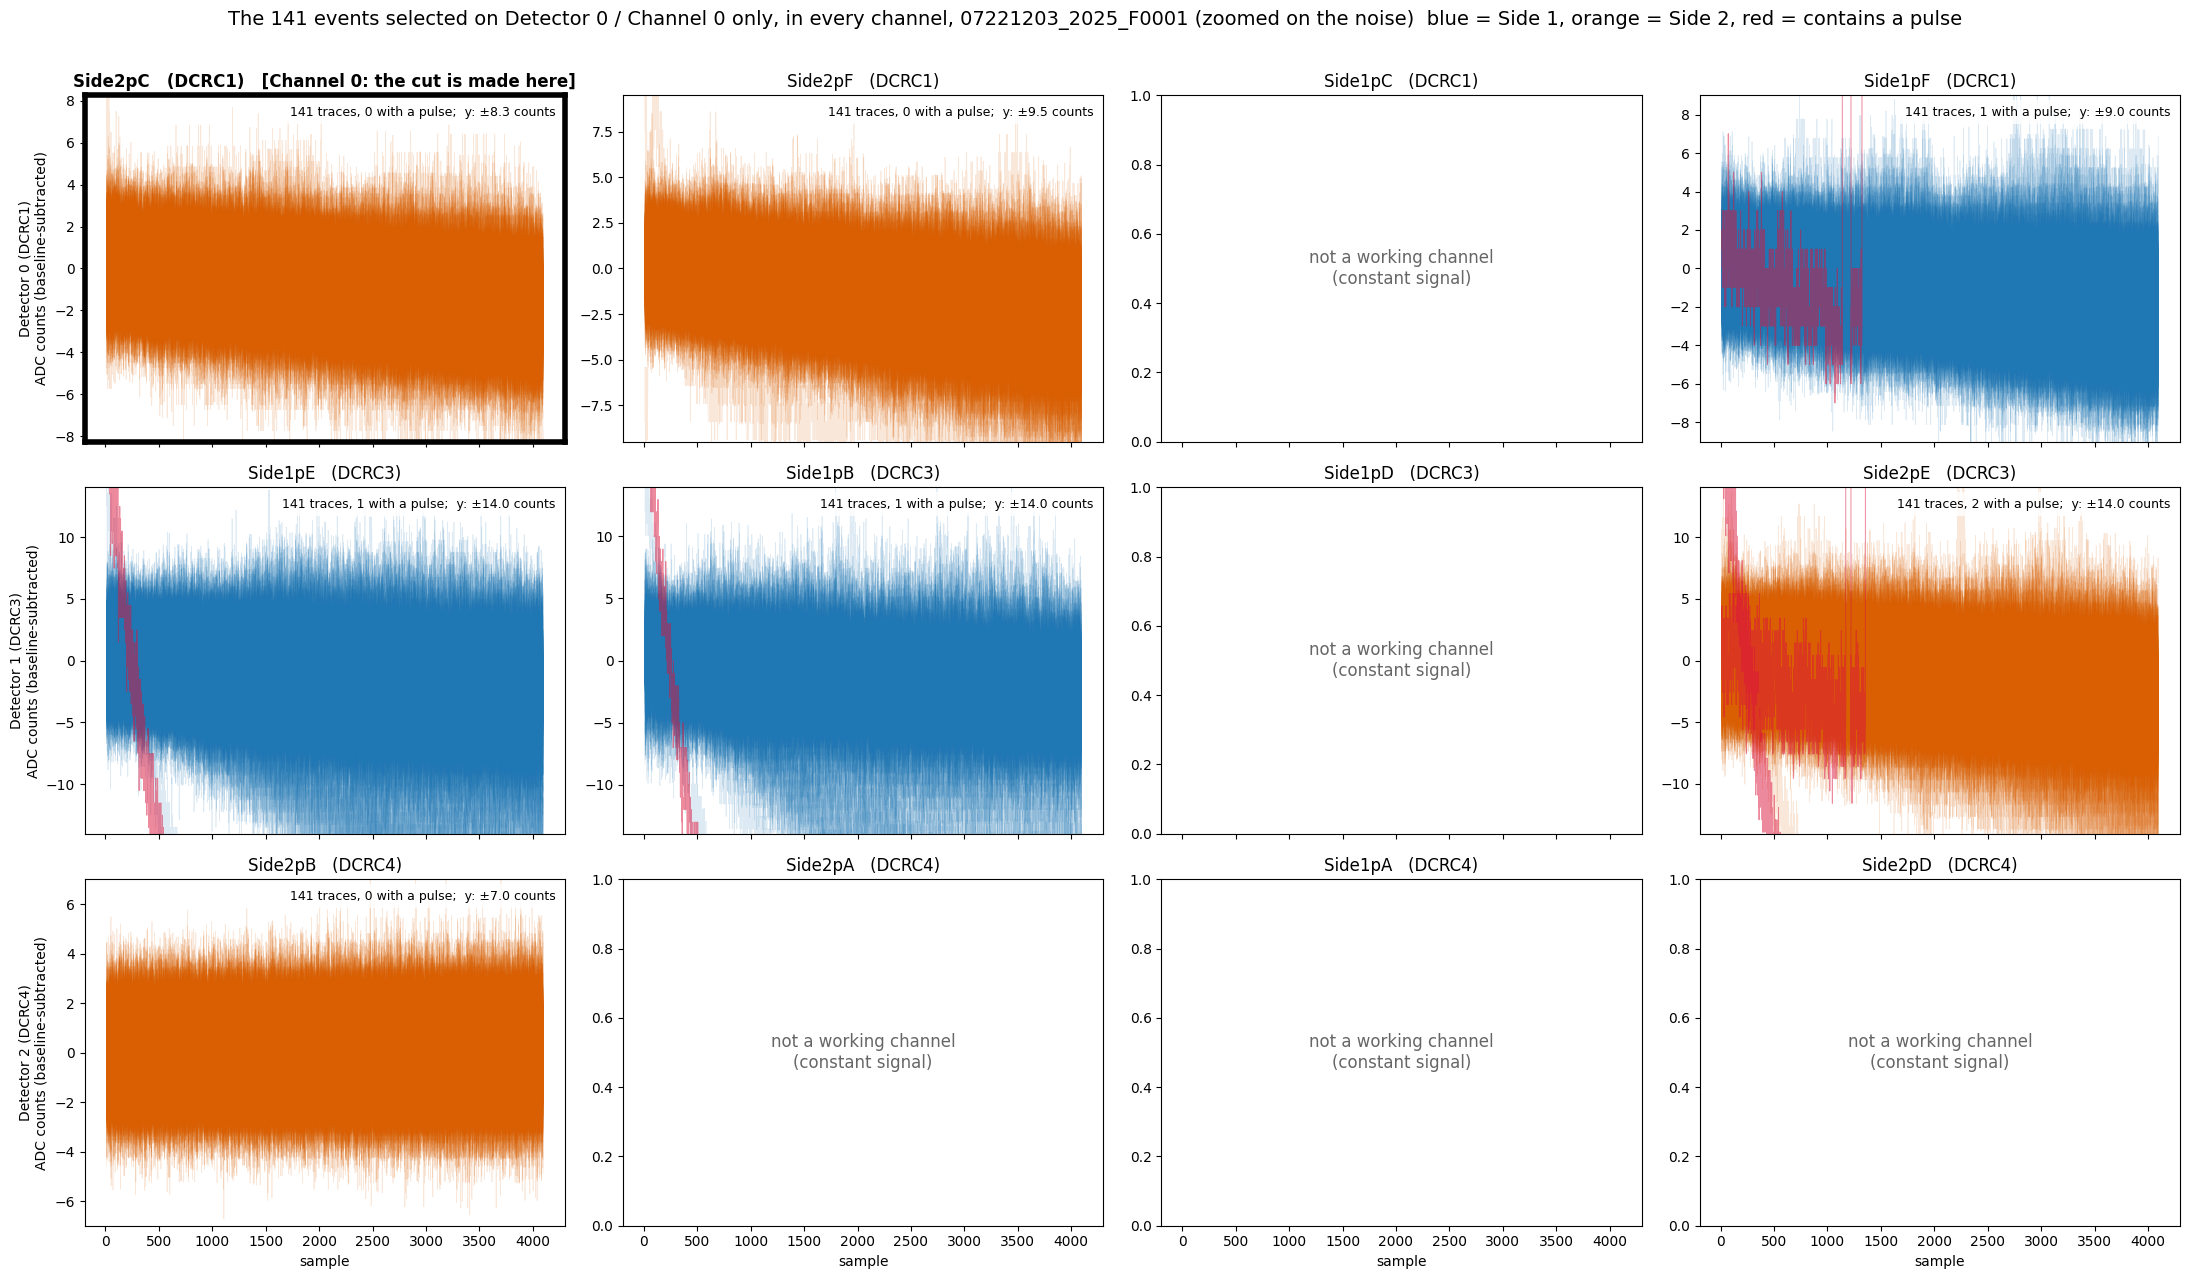

In [3]:
side_colour = {1: "#1f77b4", 2: "#d95f02"}
glitch = config_500.glitch_samples
batch_sel = {}                                              # traces of the Channel 0 selection, in every channel
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    batch_sel[key] = processed(p[sel0])
x = np.arange(glitch, glitch + batch_sel[(0, 0)].shape[-1])

def tile_figure(zoom, path):
    fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True)
    for key in KEYS:
        det, ch = key
        ax = axes[det, ch]
        c = pch.channel_info(det, ch)
        is_cut_channel = key == (0, 0)                      # the channel the cut is made on
        ax.set_title(f"{c.name}   ({c.dcrc})" + ("   [Channel 0: the cut is made here]" if is_cut_channel else ""),
                     fontsize=12, fontweight="bold" if is_cut_channel else "normal")
        if is_cut_channel:
            for spine in ax.spines.values():
                spine.set_linewidth(4)
                spine.set_edgecolor("black")
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if key not in working:
            ax.text(0.5, 0.5, "not a working channel" + chr(10) + "(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        tr = batch_sel[key]
        pulse = info[key]["pulse"][sel0]
        for trace in tr[~pulse]:
            ax.plot(x, trace, color=side_colour[c.side], linewidth=0.5, alpha=0.15)
        for trace in tr[pulse]:
            ax.plot(x, trace, color="crimson", linewidth=0.7, alpha=0.5)
        note = f"{len(tr)} traces, {pulse.sum()} with a pulse"
        if zoom:
            lim = 5 * np.median(tr[~pulse].std(axis=1))
            ax.set_ylim(-lim, lim)
            note += f";  y: " + chr(177) + f"{lim:.1f} counts"
        ax.text(0.98, 0.97, note, transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    fig.suptitle(f"The {sel0.sum()} events selected on Detector 0 / Channel 0 only, in every channel, {DUMP}"
                 + (" (zoomed on the noise)" if zoom else " (full scale)")
                 + "  blue = Side 1, orange = Side 2, red = contains a pulse", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.savefig(path, dpi=100)
    plt.show()

tile_figure(zoom=True, path=f"figures/chan0-cut-on-all-channels-zoom-{DUMP}.png")

## 3. The same traces on the full scale

The same tiles with the vertical scale left free, so that the traces with a pulse can be seen in full.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3456594178.py:14: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


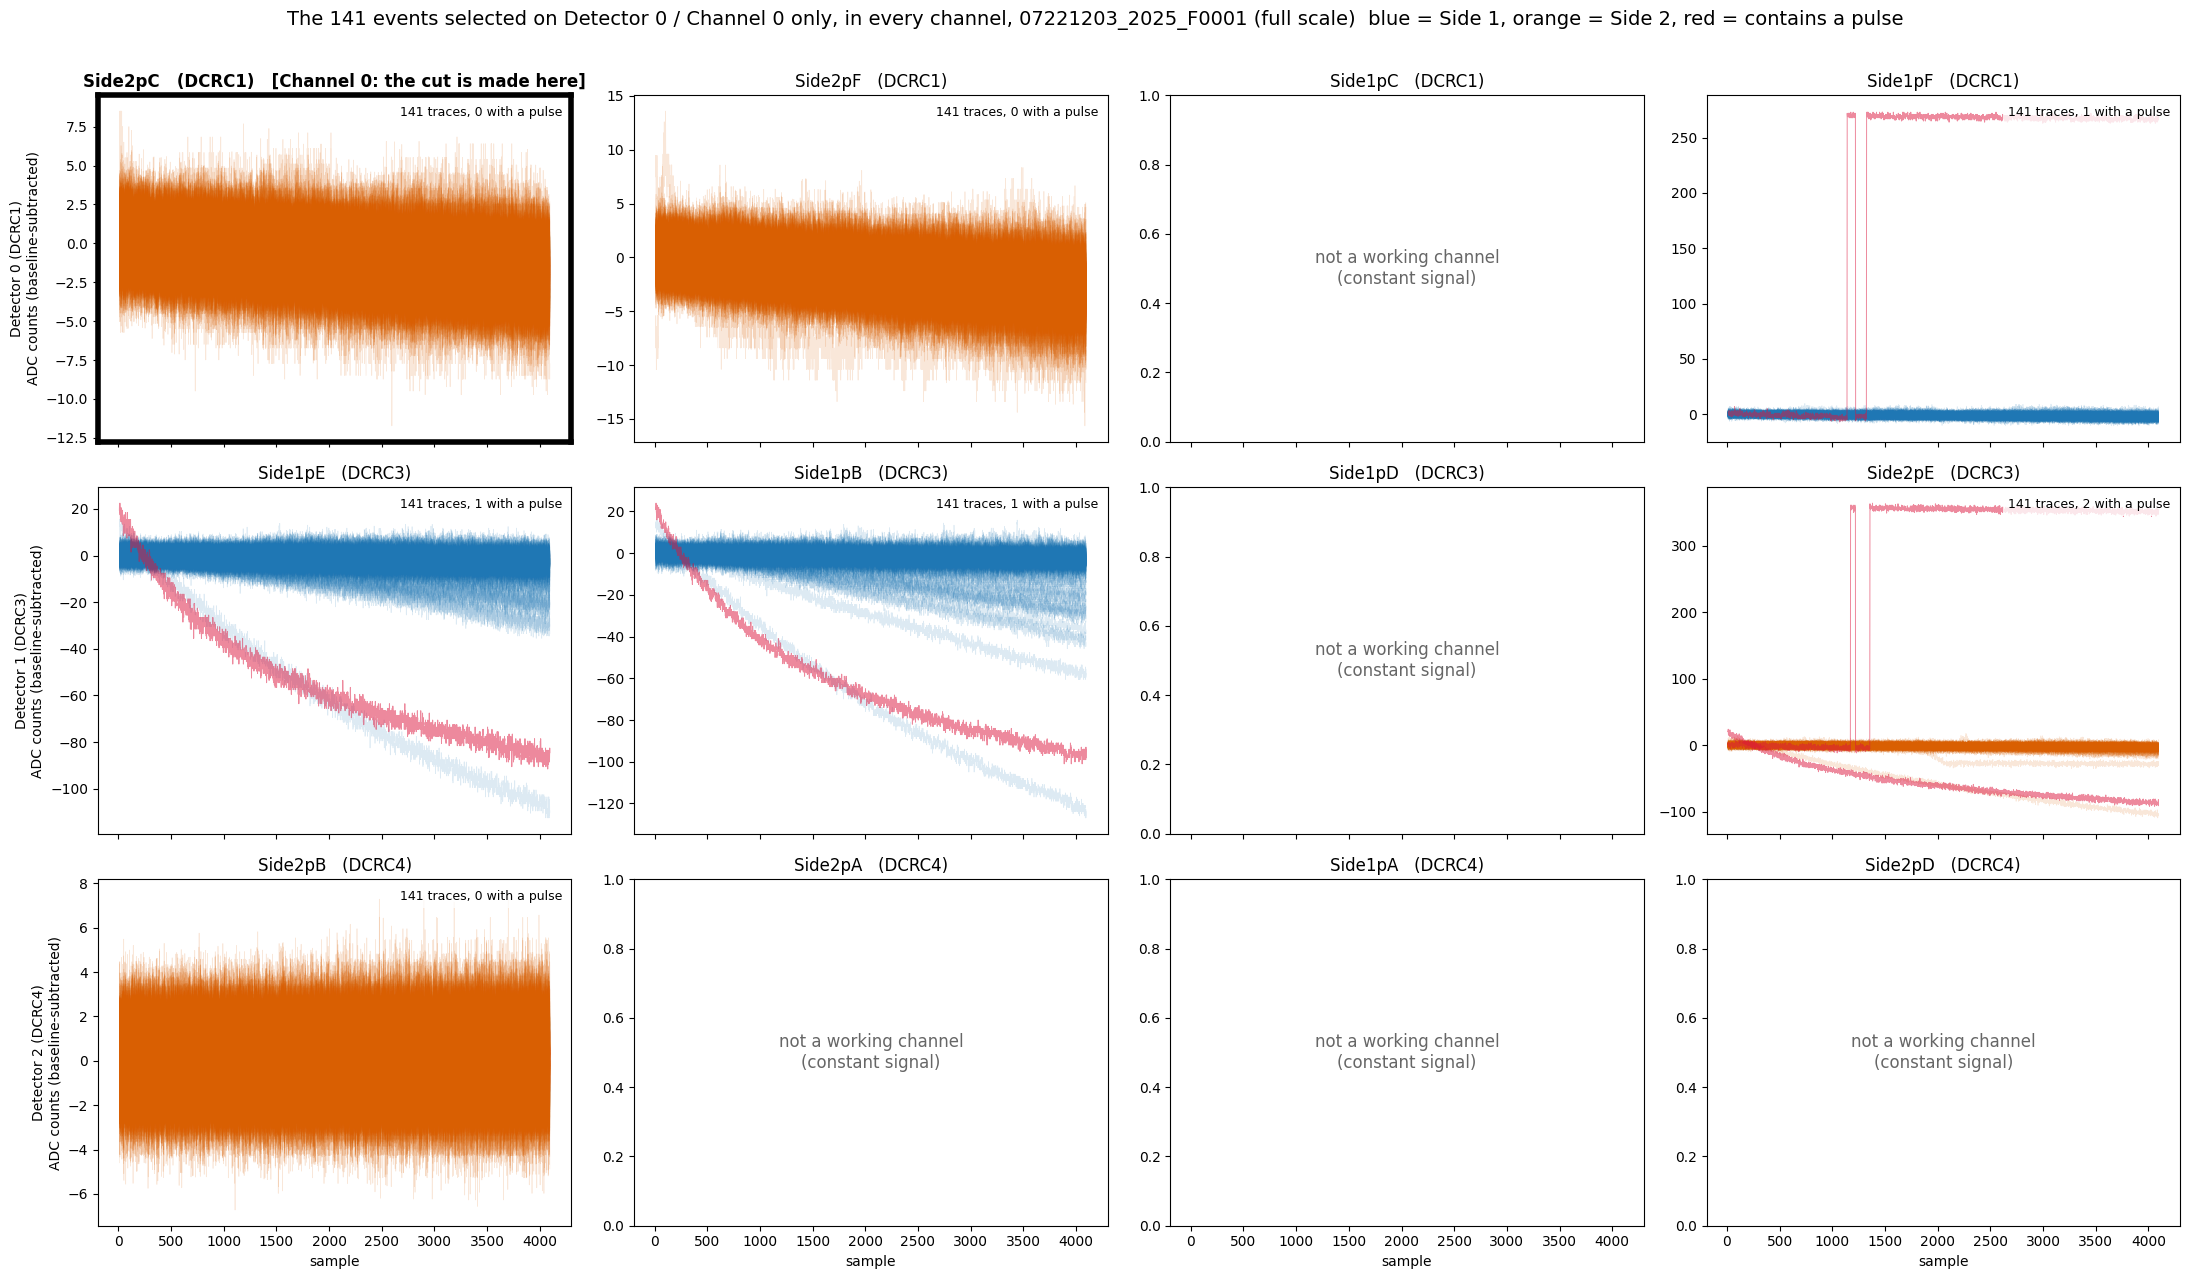

In [4]:
tile_figure(zoom=False, path=f"figures/chan0-cut-on-all-channels-full-{DUMP}.png")

## 4. How contaminated is the selection in the other channels?

For each channel, among the events of the Channel 0 selection: how many contain a pulse, how many pass that channel's own quiet-noise cut, and the median and the largest sag of the baseline (the drift, in counts across the trace). A perfect Channel 0 cut would give no pulse and a pass for every event in every channel. The last lines count the events that are clean in **every** working channel and those with a pulse in **at least one** other channel.

In [5]:
print(f"{'channel':<28}{'with a pulse':>14}{'pass own cut':>14}{'median drift':>14}{'worst drift':>13}")
for key in working:
    d = info[key]["drift"][sel0]
    print(f"{short_label(*key):<28}{int(info[key]['pulse'][sel0].sum()):>14}{int(info[key]['quiet'][sel0].sum()):>14}{np.median(d):>14.1f}{d.min():>13.1f}")
others = [k for k in working if k != (0, 0)]
any_pulse = np.any([info[k]["pulse"] for k in others], axis=0)
all_quiet = np.all([info[k]["quiet"] for k in working], axis=0)
print()
print(f"events of the Channel 0 selection: {sel0.sum()}")
print(f"  with a pulse in at least one other working channel: {(sel0 & any_pulse).sum()}")
print(f"  that pass the quiet-noise cut in every working channel: {(sel0 & all_quiet).sum()}")

channel                       with a pulse  pass own cut  median drift  worst drift
Side2pC (DCRC1)                          0           141          -2.1         -5.6
Side2pF (DCRC1)                          0            81          -3.0        -10.5
Side1pF (DCRC1)                          1            78          -2.5         -6.8
Side1pE (DCRC3)                          1            95          -3.0       -116.9
Side1pB (DCRC3)                          1            71          -3.2       -132.7
Side2pE (DCRC3)                          2           108          -3.0       -112.5
Side2pB (DCRC4)                          0           130           0.0         -2.2

events of the Channel 0 selection: 141
  with a pulse in at least one other working channel: 2
  that pass the quiet-noise cut in every working channel: 31


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


## 5. Compared with the global cut

The global cut of the noise notebook keeps a random only if it passes the quiet-noise cut in **every** working channel (31 events). The Channel 0 selection is larger, because it ignores the other six working channels. This section puts the two side by side: how many events each keeps, how they overlap, and how the selection that is rejected by the global cut breaks down.

In [6]:
global_keep = is_random & np.all([info[k]["quiet"] for k in working], axis=0)
print(f"Channel 0 cut only:        {sel0.sum()} events")
print(f"global cut (all channels): {global_keep.sum()} events")
print(f"global cut inside the Channel 0 selection: {(global_keep & sel0).sum()} of {global_keep.sum()}")
print()
extra = sel0 & ~global_keep
print(f"events kept by the Channel 0 cut but rejected by the global cut: {extra.sum()}")
print(f"  of those, with a pulse in at least one other working channel: {(extra & any_pulse).sum()}")
print(f"  of those, pulse-free but failing the quiet cut in some other channel (a ramp): {(extra & ~any_pulse).sum()}")
fails = {pch.channel_name(*k): int((extra & ~info[k]["quiet"]).sum()) for k in others}
print("  rejected events by the channel that rejects them (an event can be rejected by several):")
for name, n in fails.items():
    print(f"    {name:<9}{n:>4}")

Channel 0 cut only:        141 events
global cut (all channels): 31 events
global cut inside the Channel 0 selection: 31 of 31

events kept by the Channel 0 cut but rejected by the global cut: 110
  of those, with a pulse in at least one other working channel: 2
  of those, pulse-free but failing the quiet cut in some other channel (a ramp): 108
  rejected events by the channel that rejects them (an event can be rejected by several):
    Side2pF    60
    Side1pF    63
    Side1pE    46
    Side1pB    70
    Side2pE    33
    Side2pB    11


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\736470550.py:10: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  fails = {pch.channel_name(*k): int((extra & ~info[k]["quiet"]).sum()) for k in others}


## 6. How good is the Channel 0 cut on the other channels? (this dump only)

- **It keeps pulses out of the other channels.** Of the 141 events it selects, only 2 contain a pulse in any other working channel (the red traces of section 3): one with a step of about 270 to 360 counts in `Side1pF` and `Side2pE`, and one with a long exponential decay (from about +20 to -90 counts across the trace) in the three DCRC3 channels. That is 1.4% of the selection. DCRC4's `Side2pB` has none.
- **It does not guarantee a flat baseline in the other channels.** Only 71 to 130 of the 141 events pass the other channels' own quiet-noise cut (`Side1pB` 71, `Side1pF` 78, `Side2pF` 81, `Side1pE` 95, `Side2pE` 108, `Side2pB` 130). Just 31 events, 22% of the selection, pass in every working channel, and those 31 are the global cut. Of the 110 that do not, 108 contain no pulse at all: they fail because of a baseline ramp in at least one other channel. `Side1pB` rejects the most (70 of the 110), then `Side1pF` (63), `Side2pF` (60) and `Side1pE` (46).
- **The ramps in the other channels can be much larger than anything Channel 0 shows.** The median sag of the selected events is similar in every channel (2 to 3 counts across the trace), but the worst case is 6 counts in Channel 0 and 117, 133 and 113 counts in `Side1pE`, `Side1pB` and `Side2pE`. In the zoomed figure a handful of faint traces leave the noise band downwards in the DCRC3 tiles, while the Channel 0 tile has none. This fits the finding of `baseline-drift-buddy.ipynb` that the ramp is common to the channels of an event but larger in some of them, with an amplitude that depends on the channel; it has not been tested here why the Channel 0 cut lets such events through.
- **So the Channel 0 cut is a good pulse veto and a weak noise-quality cut for the other channels.** If the noise PSD is to be computed on channels other than Channel 0, the global cut (31 events) or a cut on each channel's own drift is needed, not the Channel 0 selection alone.

## 7. Cutting on one channel of each side

Section 6 says that a cut on Channel 0 alone lets baseline ramps through in the other channels. What if the cut is made on **two** channels, one on Side 2 and one on Side 1? Here the selection is: a random that passes the quiet-noise cut on `Side2pC` (Detector 0 / Channel 0, Side 2) **and** on one channel of Side 1. The Side 1 channel is chosen at the top of the cell below (`B_KEY`); the default is `Side1pB` on DCRC3, the channel that rejected the most events in section 5. The table lists what each Side 1 choice would give.

The figures are the same tiles as in section 2, now for this selection, with the **two channels the cut is made on** marked by a thick black frame and a bold title.

In [7]:
A_KEY = (0, 0)           # Side 2: Detector 0 / Channel 0, Side2pC, as in the sections above
B_KEY = (1, 1)           # Side 1: Detector 1 / Channel 1, Side1pB (DCRC3). Try (1, 0) Side1pE or (0, 3) Side1pF
assert pch.channel_info(*A_KEY).side == 2 and pch.channel_info(*B_KEY).side == 1
assert A_KEY in working and B_KEY in working

selAB = is_random & info[A_KEY]["quiet"] & info[B_KEY]["quiet"]            # <- the two-channel selection
global_keep = is_random & np.all([info[k]["quiet"] for k in working], axis=0)
others = [k for k in working if k not in (A_KEY, B_KEY)]
any_pulse = np.any([info[k]["pulse"] for k in working], axis=0)

print(f"cut on {short_label(*A_KEY)} and {short_label(*B_KEY)}: {selAB.sum()} events")
print(f"  with a pulse in a working channel: {(selAB & any_pulse).sum()}")
print(f"  that pass the quiet-noise cut in every working channel (the global cut): {(selAB & global_keep).sum()} of the {global_keep.sum()}")
print()
print(f"{'channel':<28}{'with a pulse':>14}{'pass own cut':>14}{'median drift':>14}{'worst drift':>13}")
for key in working:
    d = info[key]["drift"][selAB]
    mark = "  <- cut" if key in (A_KEY, B_KEY) else ""
    print(f"{short_label(*key):<28}{int(info[key]['pulse'][selAB].sum()):>14}{int(info[key]['quiet'][selAB].sum()):>14}{np.median(d):>14.1f}{d.min():>13.1f}{mark}")

print()
print(f"{'cut on Side2pC and':<22}{'events kept':>12}{'in the global cut':>19}{'with a pulse':>14}")
print(f"{'(Side2pC alone)':<22}{sel0.sum():>12}{(sel0 & global_keep).sum():>19}{(sel0 & any_pulse).sum():>14}")
for k in [k for k in working if pch.channel_info(*k).side == 1]:
    s = is_random & info[A_KEY]["quiet"] & info[k]["quiet"]
    print(f"{pch.channel_name(*k):<22}{s.sum():>12}{(s & global_keep).sum():>19}{(s & any_pulse).sum():>14}")
print(f"{'(the global cut)':<22}{global_keep.sum():>12}{global_keep.sum():>19}{(global_keep & any_pulse).sum():>14}")

cut on Side2pC (DCRC1) and Side1pB (DCRC3): 71 events
  with a pulse in a working channel: 0
  that pass the quiet-noise cut in every working channel (the global cut): 31 of the 31

channel                       with a pulse  pass own cut  median drift  worst drift
Side2pC (DCRC1)                          0            71          -2.0         -5.6  <- cut
Side2pF (DCRC1)                          0            52          -2.5         -8.0
Side1pF (DCRC1)                          0            51          -1.9         -5.1
Side1pE (DCRC3)                          0            60          -2.4         -6.6
Side1pB (DCRC3)                          0            71          -2.3         -8.2  <- cut
Side2pE (DCRC3)                          0            65          -2.4         -5.6
Side2pB (DCRC4)                          0            68           0.1         -2.2

cut on Side2pC and     events kept  in the global cut  with a pulse
(Side2pC alone)                141                 31        

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\364051183.py:3: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  assert pch.channel_info(*A_KEY).side == 2 and pch.channel_info(*B_KEY).side == 1
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order withi

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:13: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:44: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  names = " and ".join(pch.channel_name(*k) for k in cut_keys)


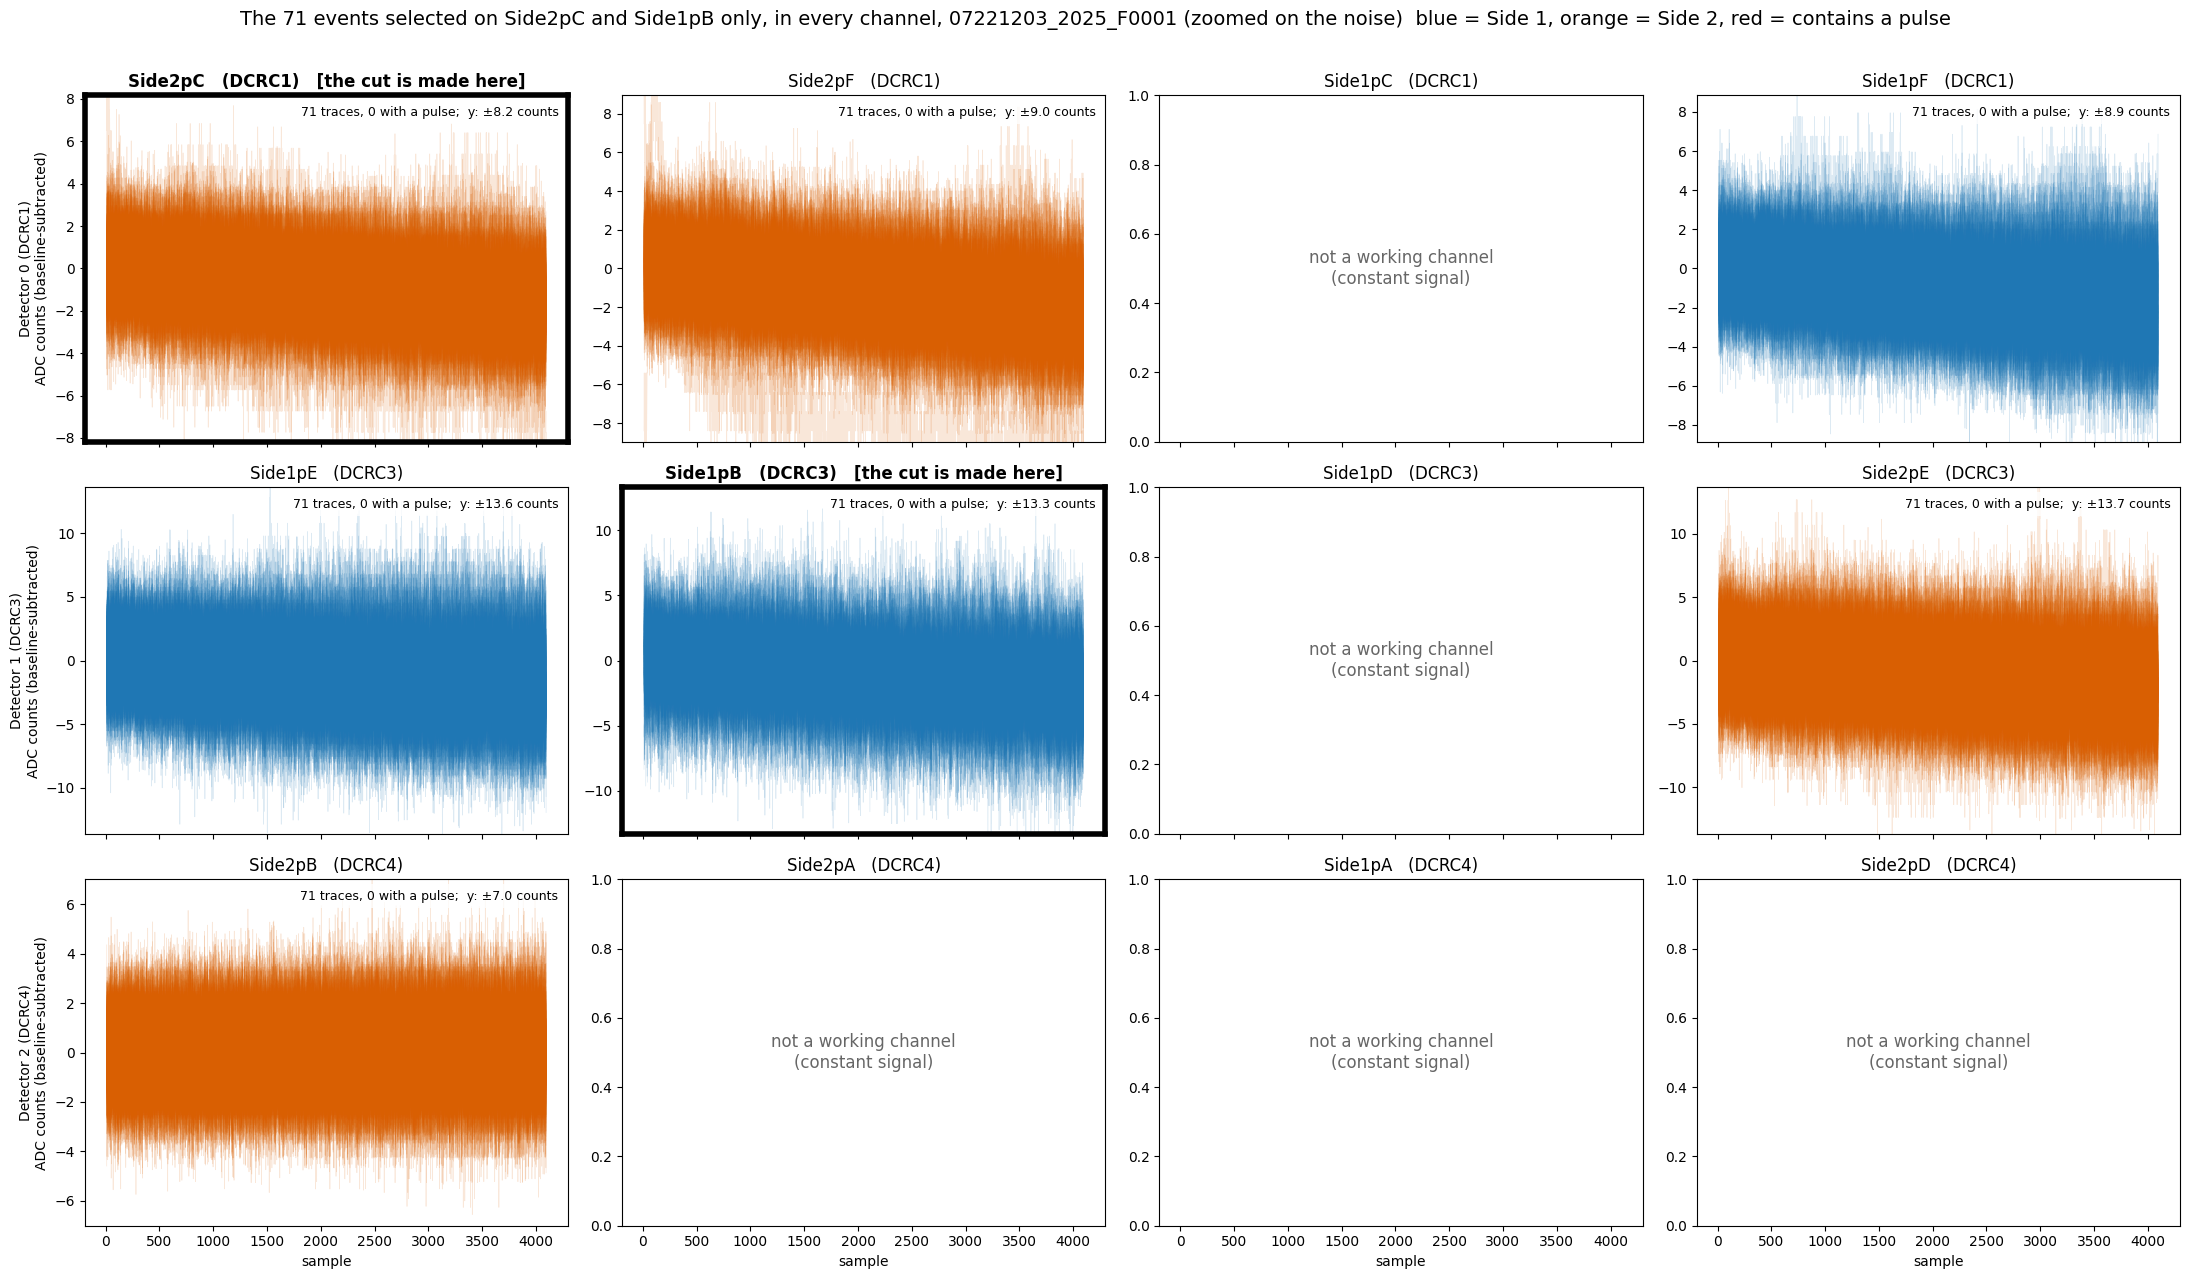

In [8]:
def tile_figure_for(selection, cut_keys, zoom, path, max_traces=None, seed=0):
    """The events of `selection` on every channel; the tiles of `cut_keys` (where the cut was made) are framed.
    With `max_traces`, only a random subset of that many events is drawn (the title says so)."""
    n_selected = int(selection.sum())
    if max_traces and n_selected > max_traces:
        chosen = np.random.default_rng(seed).choice(np.flatnonzero(selection), size=max_traces, replace=False)
        selection = np.zeros_like(selection)
        selection[chosen] = True
    fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True)
    for key in KEYS:
        det, ch = key
        ax = axes[det, ch]
        c = pch.channel_info(det, ch)
        is_cut = key in cut_keys
        ax.set_title(f"{c.name}   ({c.dcrc})" + ("   [the cut is made here]" if is_cut else ""),
                     fontsize=12, fontweight="bold" if is_cut else "normal")
        if is_cut:
            for spine in ax.spines.values():
                spine.set_linewidth(4)
                spine.set_edgecolor("black")
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if key not in working:
            ax.text(0.5, 0.5, "not a working channel" + chr(10) + "(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        tr = processed(p[selection])
        xs = np.arange(glitch, glitch + tr.shape[-1])
        pulse = info[key]["pulse"][selection]
        for trace in tr[~pulse]:
            ax.plot(xs, trace, color=side_colour[c.side], linewidth=0.5, alpha=0.15)
        for trace in tr[pulse]:
            ax.plot(xs, trace, color="crimson", linewidth=0.7, alpha=0.5)
        note = f"{len(tr)} traces, {pulse.sum()} with a pulse"
        if zoom:
            lim = 5 * np.median(tr[~pulse].std(axis=1))
            ax.set_ylim(-lim, lim)
            note += ";  y: " + chr(177) + f"{lim:.1f} counts"
        ax.text(0.98, 0.97, note, transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    names = " and ".join(pch.channel_name(*k) for k in cut_keys)
    shown_n = f"{selection.sum()} of the {n_selected}" if selection.sum() < n_selected else f"The {n_selected}"
    fig.suptitle(f"{shown_n} events selected on {names} only, in every channel, {DUMP}"
                 + (" (zoomed on the noise)" if zoom else " (full scale)")
                 + "  blue = Side 1, orange = Side 2, red = contains a pulse", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.savefig(path, dpi=100)
    plt.show()

tile_figure_for(selAB, (A_KEY, B_KEY), zoom=True, path=f"figures/cut-on-S1-and-S2-zoom-{DUMP}.png")

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:13: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:44: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  names = " and ".join(pch.channel_name(*k) for k in cut_keys)


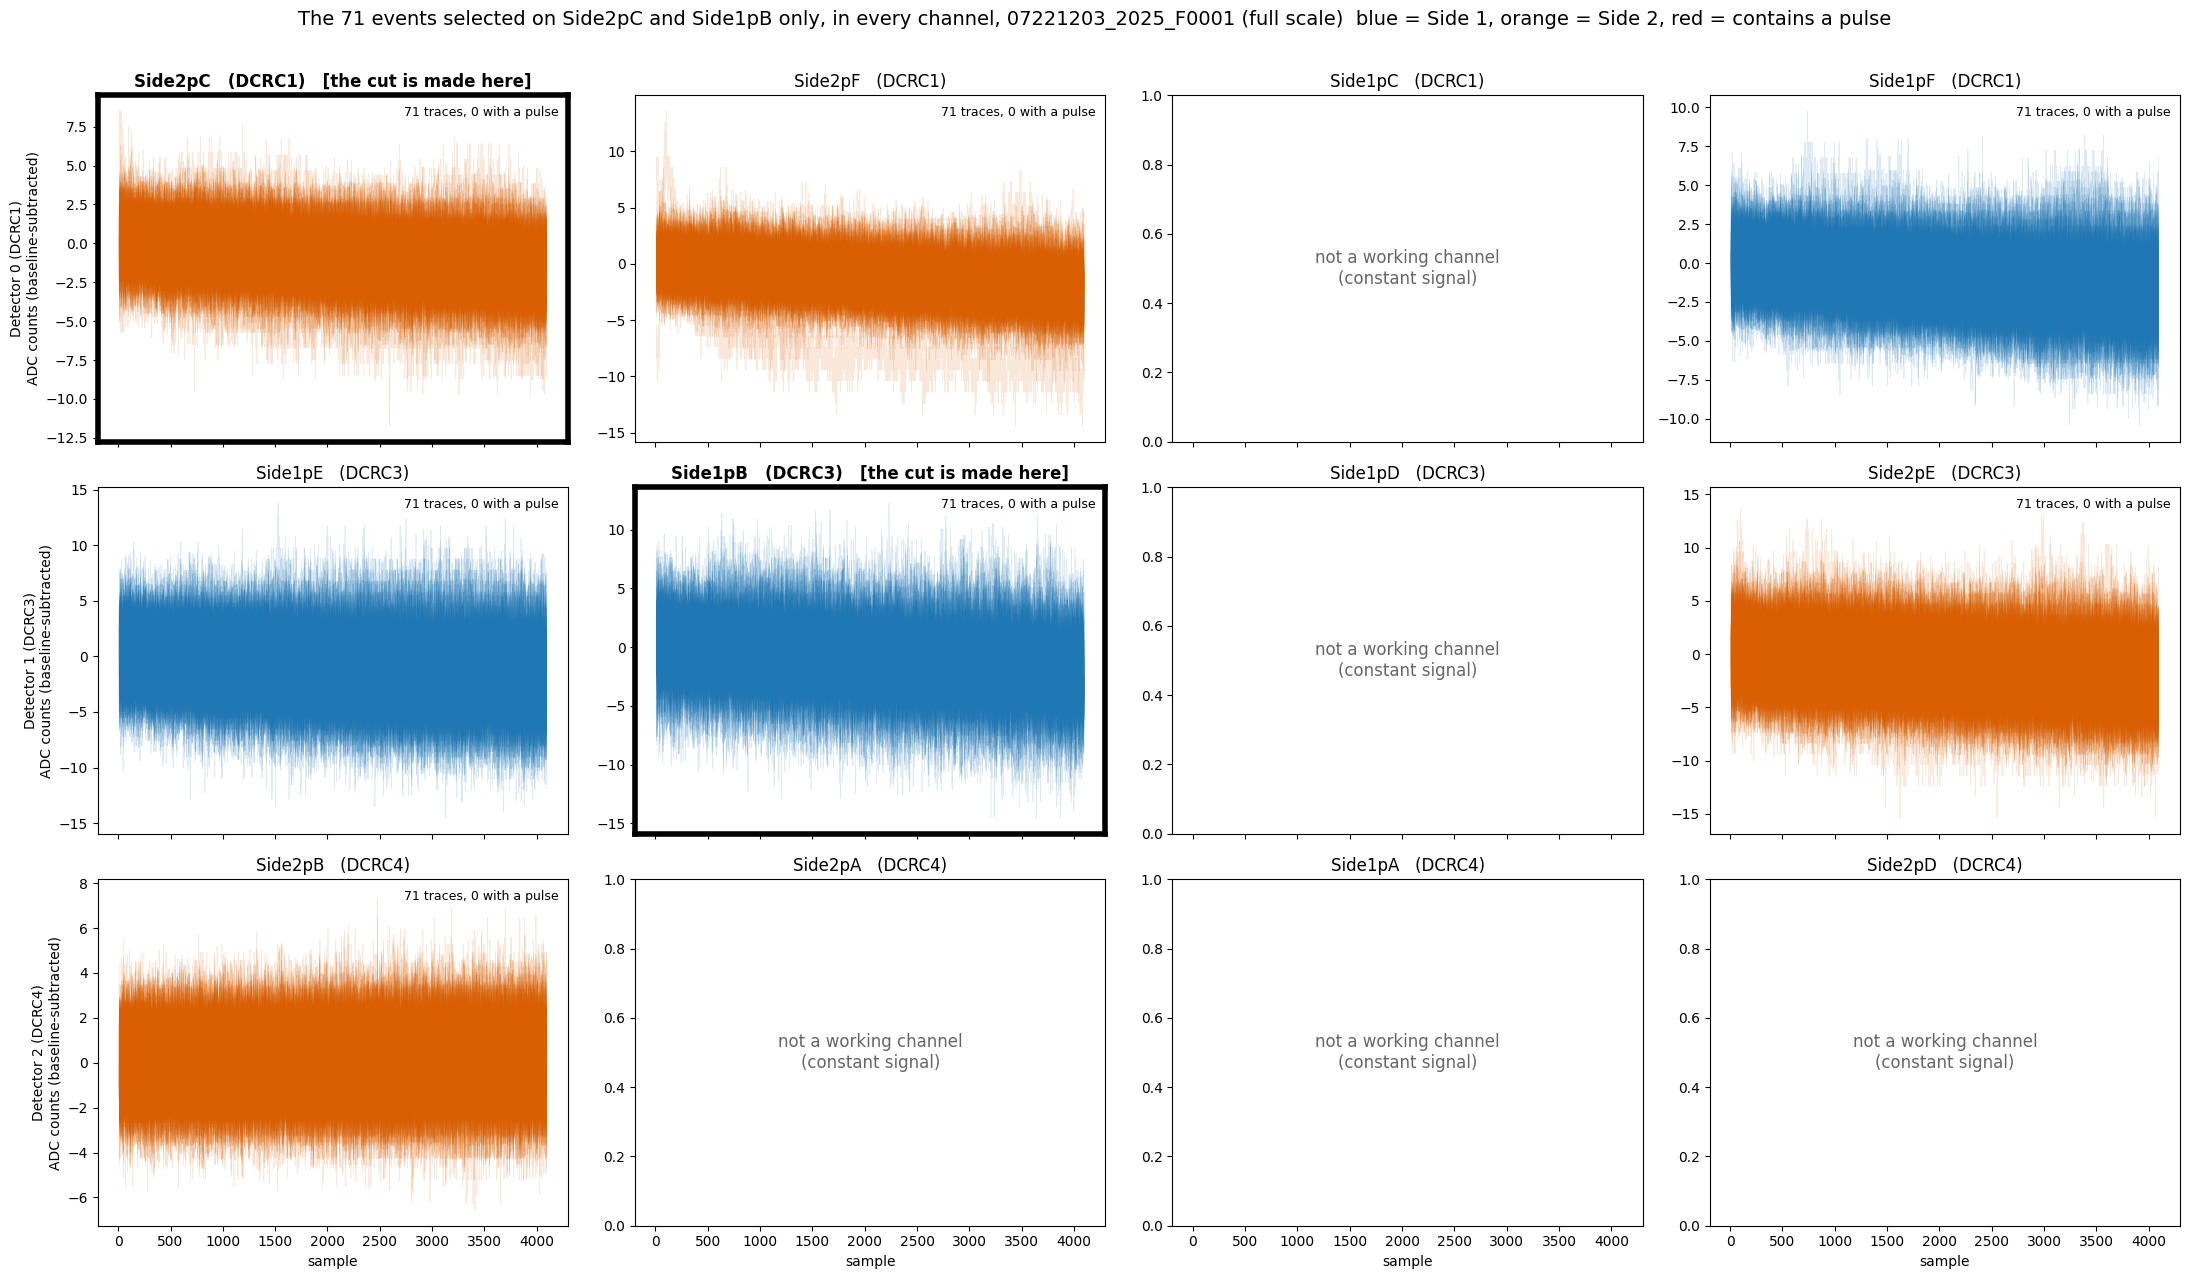

In [9]:
tile_figure_for(selAB, (A_KEY, B_KEY), zoom=False, path=f"figures/cut-on-S1-and-S2-full-{DUMP}.png")

### 7.1 What cutting on one channel of each side gives (this dump only)

- **It removes the large ramps and the pulses.** Cutting on `Side2pC` and `Side1pB` keeps 71 of the 141 events of section 2. None of the 71 contains a pulse in any working channel (the Channel 0 cut alone let 2 through), and the worst baseline sag in any channel is now 5 to 8 counts, where it was 113 to 133 counts in the three DCRC3 channels. The DCRC3 tiles no longer have traces leaving the noise band.
- **The other channels agree with it better, but not fully.** The share of the 71 events that pass each other channel's own quiet-noise cut is 73% for `Side2pF` (52), 72% for `Side1pF` (51), 85% for `Side1pE` (60), 92% for `Side2pE` (65) and 96% for `Side2pB` (68), against 57%, 55%, 67%, 77% and 92% for the Channel 0 cut alone. Only 31 of the 71 (44%) pass in every working channel, so the global cut is still stricter.
- **The choice of the Side 1 channel matters.** With `Side1pF` the cut keeps 78 events, with `Side1pE` 95 and with `Side1pB` 71. All three contain the 31 events of the global cut and none contains a pulse. `Side1pB` is the strictest, which fits it rejecting the most events in section 5.
- **What it says for the PSD.** A cut on one channel of each side is a good pulse veto and removes the large ramps. The channels that remain least consistent with it are `Side2pF` and `Side1pF`, on DCRC1. If the PSD is needed for all channels, the global cut remains the safest choice, at the price of 31 events instead of 71.

## 8. The opposite cut: pulses and pulse tails on `Side2pC` and `Side1pB`

The same two channels, with the cut turned round. Here the events kept are the randoms whose trace is **too big to be noise** in both `Side2pC` (Side 2) and `Side1pB` (Side 1): the excursion after the pretrigger window is more than 10^0.7 (about 5) times the baseline scatter, the upper edge of the Tight band. That is what the cut rejects on its high side: a pulse in the trace, or the **tail of an earlier pulse**, which shows as a large baseline ramp.

The tiles are those of the sections above, with the two channels the cut is made on framed in black. A trace that contains a pulse in that channel, a fast step or a peak inside the trace, is drawn in red; the others (a ramp or the tail of a pulse) are drawn in the colour of their side. The vertical scale is free, because these traces are large. To keep the figure readable, a random subset of 150 of the selected events is drawn; the counts below use all of them.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\2896876831.py:10: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"randoms: {is_random.sum()};  too big in {pch.channel_name(*A_KEY)}: {(is_random & ratio_high[A_KEY]).sum()},"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\2896876831.py:11: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  f"  in {pch.channel_name(*B_KEY)}: {(is_random & ratio_high[B_KEY]).sum()},  in both: {selPT.sum()}")
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order 

randoms: 1008;  too big in Side2pC: 831,  in Side1pB: 848,  in both: 781

of the 781 events too big in both channels:
  a pulse in both channels:                  157
  a pulse in one of the two only:            54
  no pulse in either (a ramp or a tail):     570

channel                       with a pulse  median drift  worst drift
Side2pC (DCRC1)                        165          -7.4       -328.6
Side2pF (DCRC1)                        191         -11.5       -621.6
Side1pF (DCRC1)                        168          -9.0       -439.6
Side1pE (DCRC3)                        187         -14.2       -723.8
Side1pB (DCRC3)                        203         -14.7       -870.2
Side2pE (DCRC3)                        175         -13.9       -636.4
Side2pB (DCRC4)                          0          -0.0         -2.6


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:13: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:44: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  names = " and ".join(pch.channel_name(*k) for k in cut_keys)


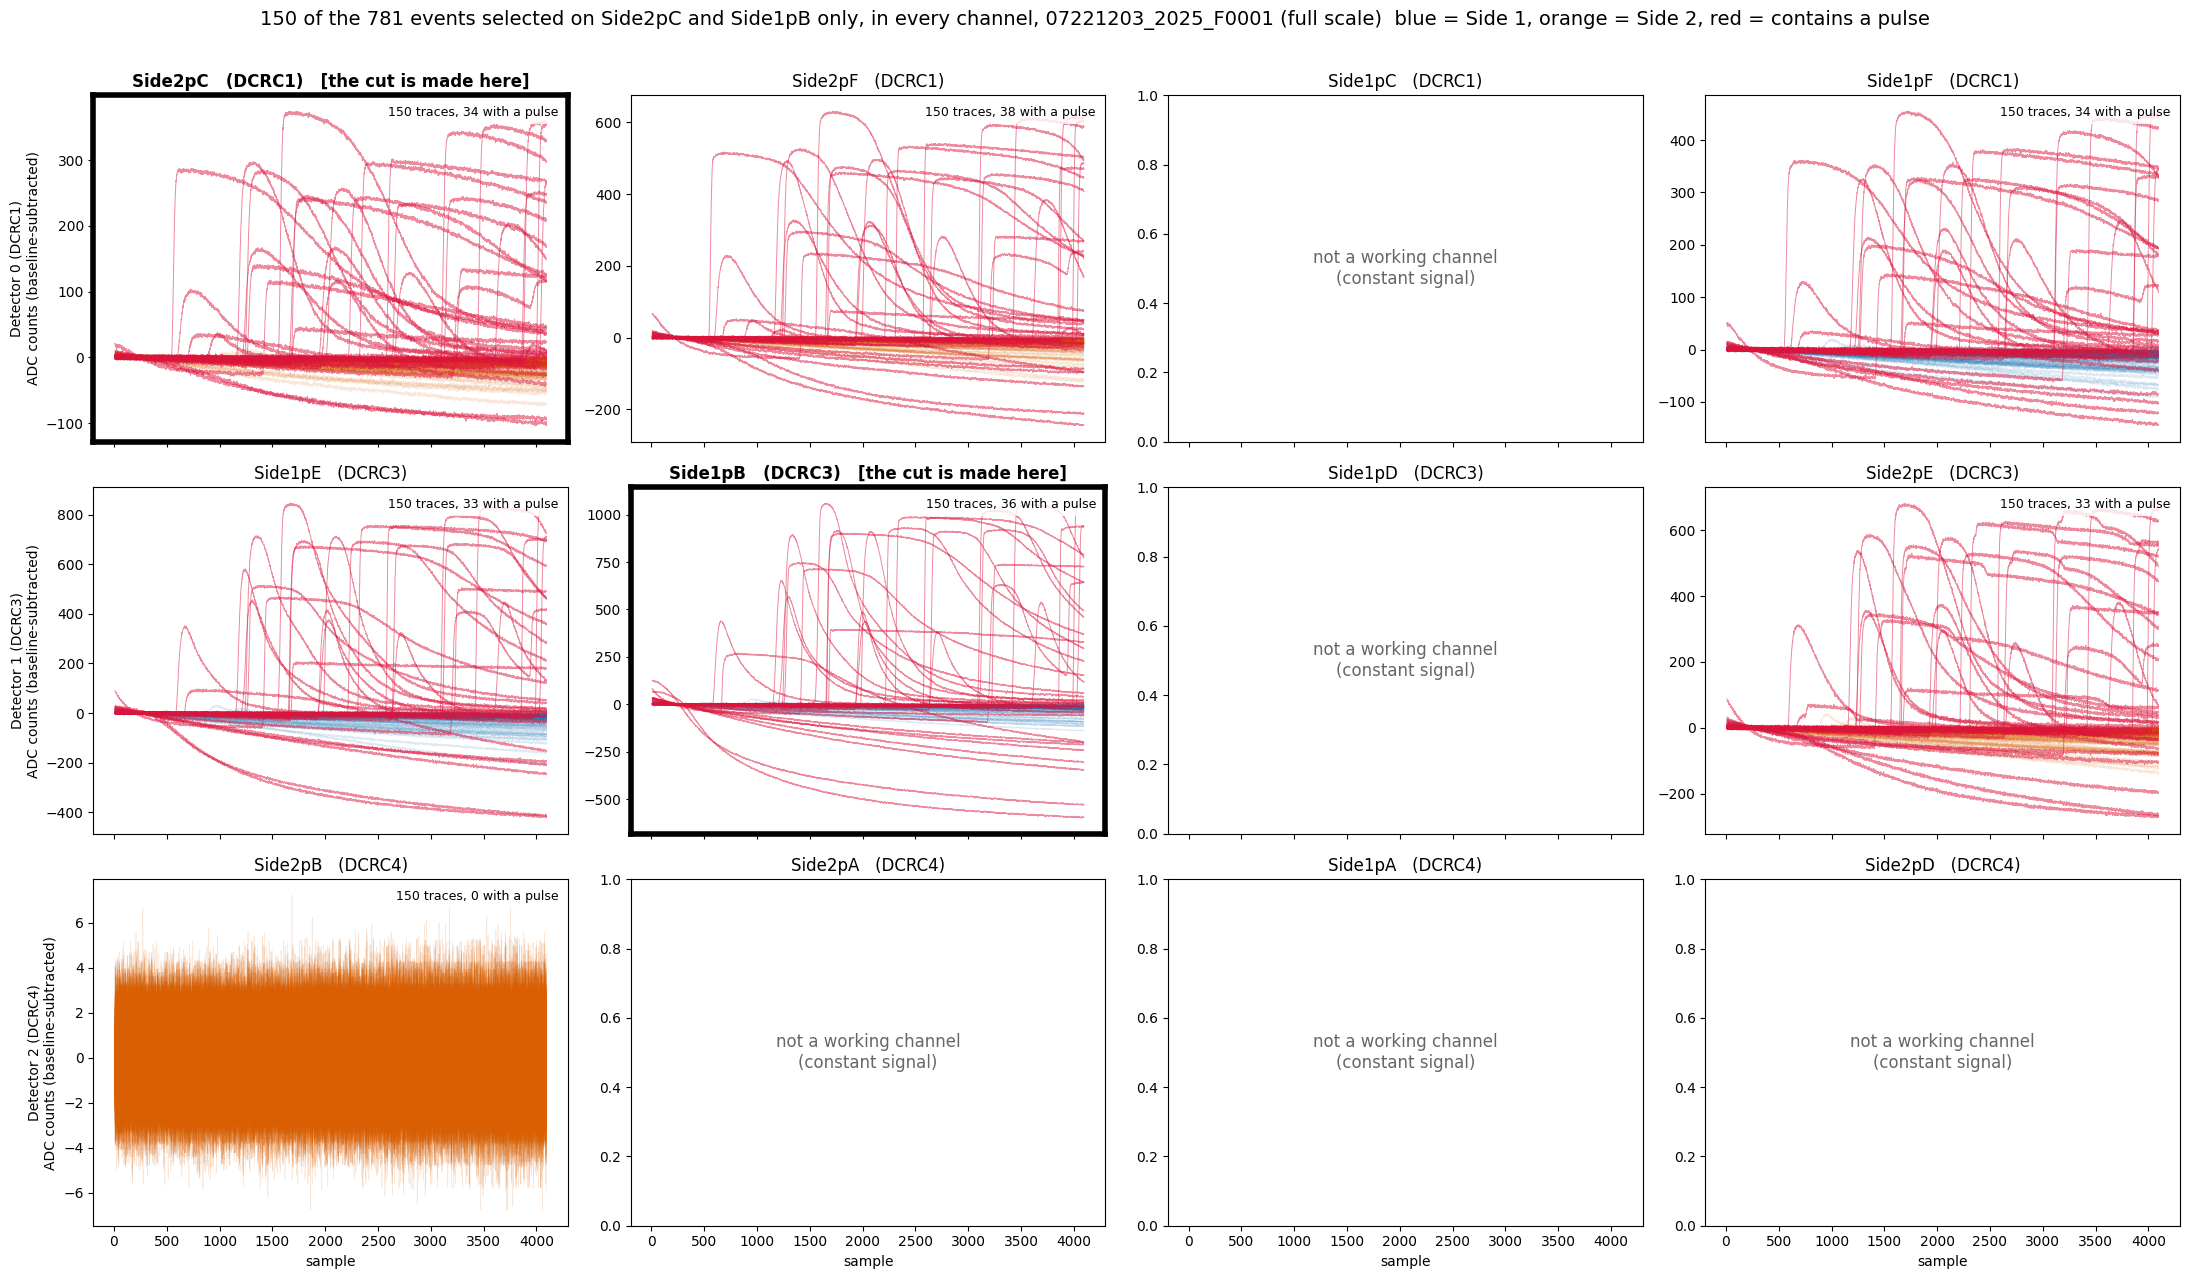

In [10]:
# Events that are too big to be noise in both channels the cut is made on
ratio_high = {}
for key in (A_KEY, B_KEY):
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    with np.errstate(all="ignore"):
        ratio_high[key] = np.log10(pq.excursion_ratio(p, config_500)) >= 0.7        # above the Tight band

selPT = is_random & ratio_high[A_KEY] & ratio_high[B_KEY]                          # <- pulse-like events and pulse tails
pulse_A, pulse_B = info[A_KEY]["pulse"], info[B_KEY]["pulse"]
print(f"randoms: {is_random.sum()};  too big in {pch.channel_name(*A_KEY)}: {(is_random & ratio_high[A_KEY]).sum()},"
      f"  in {pch.channel_name(*B_KEY)}: {(is_random & ratio_high[B_KEY]).sum()},  in both: {selPT.sum()}")
print()
print(f"of the {selPT.sum()} events too big in both channels:")
print(f"  a pulse in both channels:                  {(selPT & pulse_A & pulse_B).sum()}")
print(f"  a pulse in one of the two only:            {(selPT & (pulse_A ^ pulse_B)).sum()}")
print(f"  no pulse in either (a ramp or a tail):     {(selPT & ~pulse_A & ~pulse_B).sum()}")
print()
print(f"{'channel':<28}{'with a pulse':>14}{'median drift':>14}{'worst drift':>13}")
for key in working:
    d = info[key]["drift"][selPT]
    print(f"{short_label(*key):<28}{int(info[key]['pulse'][selPT].sum()):>14}{np.median(d):>14.1f}{d.min():>13.1f}")

tile_figure_for(selPT, (A_KEY, B_KEY), zoom=False, path=f"figures/pulses-and-tails-on-S1-and-S2-{DUMP}.png", max_traces=150)

### 8.1 What the pulses and tails look like (this dump only)

- **Most randoms are too big to be noise in these two channels.** 831 of the 1008 randoms are above the Tight band in `Side2pC`, 848 in `Side1pB`, and 781 (77%) in both.
- **Most of those are not pulses.** Of the 781, 157 contain a pulse in both channels and 54 in one of the two, while 570 (73%) contain none in either: they are baseline ramps, or the tails of earlier pulses.
- **The pulses are large.** The red traces are fast steps and peaks of 100 to about 1000 counts followed by a slow recovery, with several in one trace in some cases (a second pulse arriving on the tail of the first).
- **The tails look like earlier pulses.** Several traces start high and decay towards large negative values across the 4096 samples (to more than -500 counts in `Side1pB`), as if a pulse that arrived before the trace began were still recovering. This is read from the figure and has not been tested against the timing of the previous events.
- **The ramps are much bigger than in the quiet selections.** The median drift of these events is 7 to 15 counts in the six DCRC1 and DCRC3 channels (against 2 to 3 for the quiet selection of section 7), and the worst is 330 to 870 counts.
- **`Side2pB` (DCRC4) cannot tell these events apart.** It shows only flat noise here, with no pulse and no ramp in any of the 150 drawn events.

## 9. The events that pass the `Side2pC` cut but have a pulse or a big tail

Section 2 shows that the Channel 0 cut keeps almost no pulses, and that a few of its events have something large in another channel. This section picks exactly those. Start from the events that **pass the `Side2pC` cut** (the 141 of section 2, which are quiet in `Side2pC` by construction). Keep only the ones that have, in at least one working channel:

- a **pulse** (the scatter left after removing a straight line is more than 3 times the median of that channel, as in section 1), or
- a **big tail**: a baseline sag of more than `TAIL_DRIFT` counts across the trace (the drift of section 1), which is what the tail of an earlier pulse looks like. The threshold is set at the top of the cell below; the table beside it shows how many events each value would give.

Each event is drawn in **its own colour**, the same in every tile, so that one event can be followed from channel to channel, and the legend gives the event numbers. The tile of `Side2pC`, the channel the cut is made on, is framed. The vertical scale is free because the traces are large.

events that pass the Side2pC cut: 141
sag larger than (counts)      events with a big tail
10                                                22
20                                                15
30                                                 9
50                                                 3
100                                                1

with a pulse in some working channel: 2;  with a big tail (sag over 30 counts): 9;  either: 10

  event  pulse in                                 worst sag  in channel
  10027  -                                             -133  Side1pB
  10034  Side1pE, Side1pB, Side2pE                     -100  Side1pB
  10253  -                                              -32  Side1pB
  10342  -                                              -40  Side2pE
  10482  -                                              -39  Side1pB
  10550  Side1pF, Side2pE                               -11  Side1pE
  10652  -                                              -43  

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\887594720.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"{event_numbers[e]:>7}  {', '.join(pulses_in) or '-':<40}{drift_all[j, e]:>10.0f}  {pch.channel_name(*working[j])}")
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\887594720.py:19: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  pulses_in = [pch.channel_name(*k) for k, f in zip(working, pulse_all[:, e]) if f]


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\887594720.py:31: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\887594720.py:59: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  fig.suptitle(f"The {len(idx)} events that pass the {pch.channel_name(*cut_key)} cut and have a pulse or a big tail "


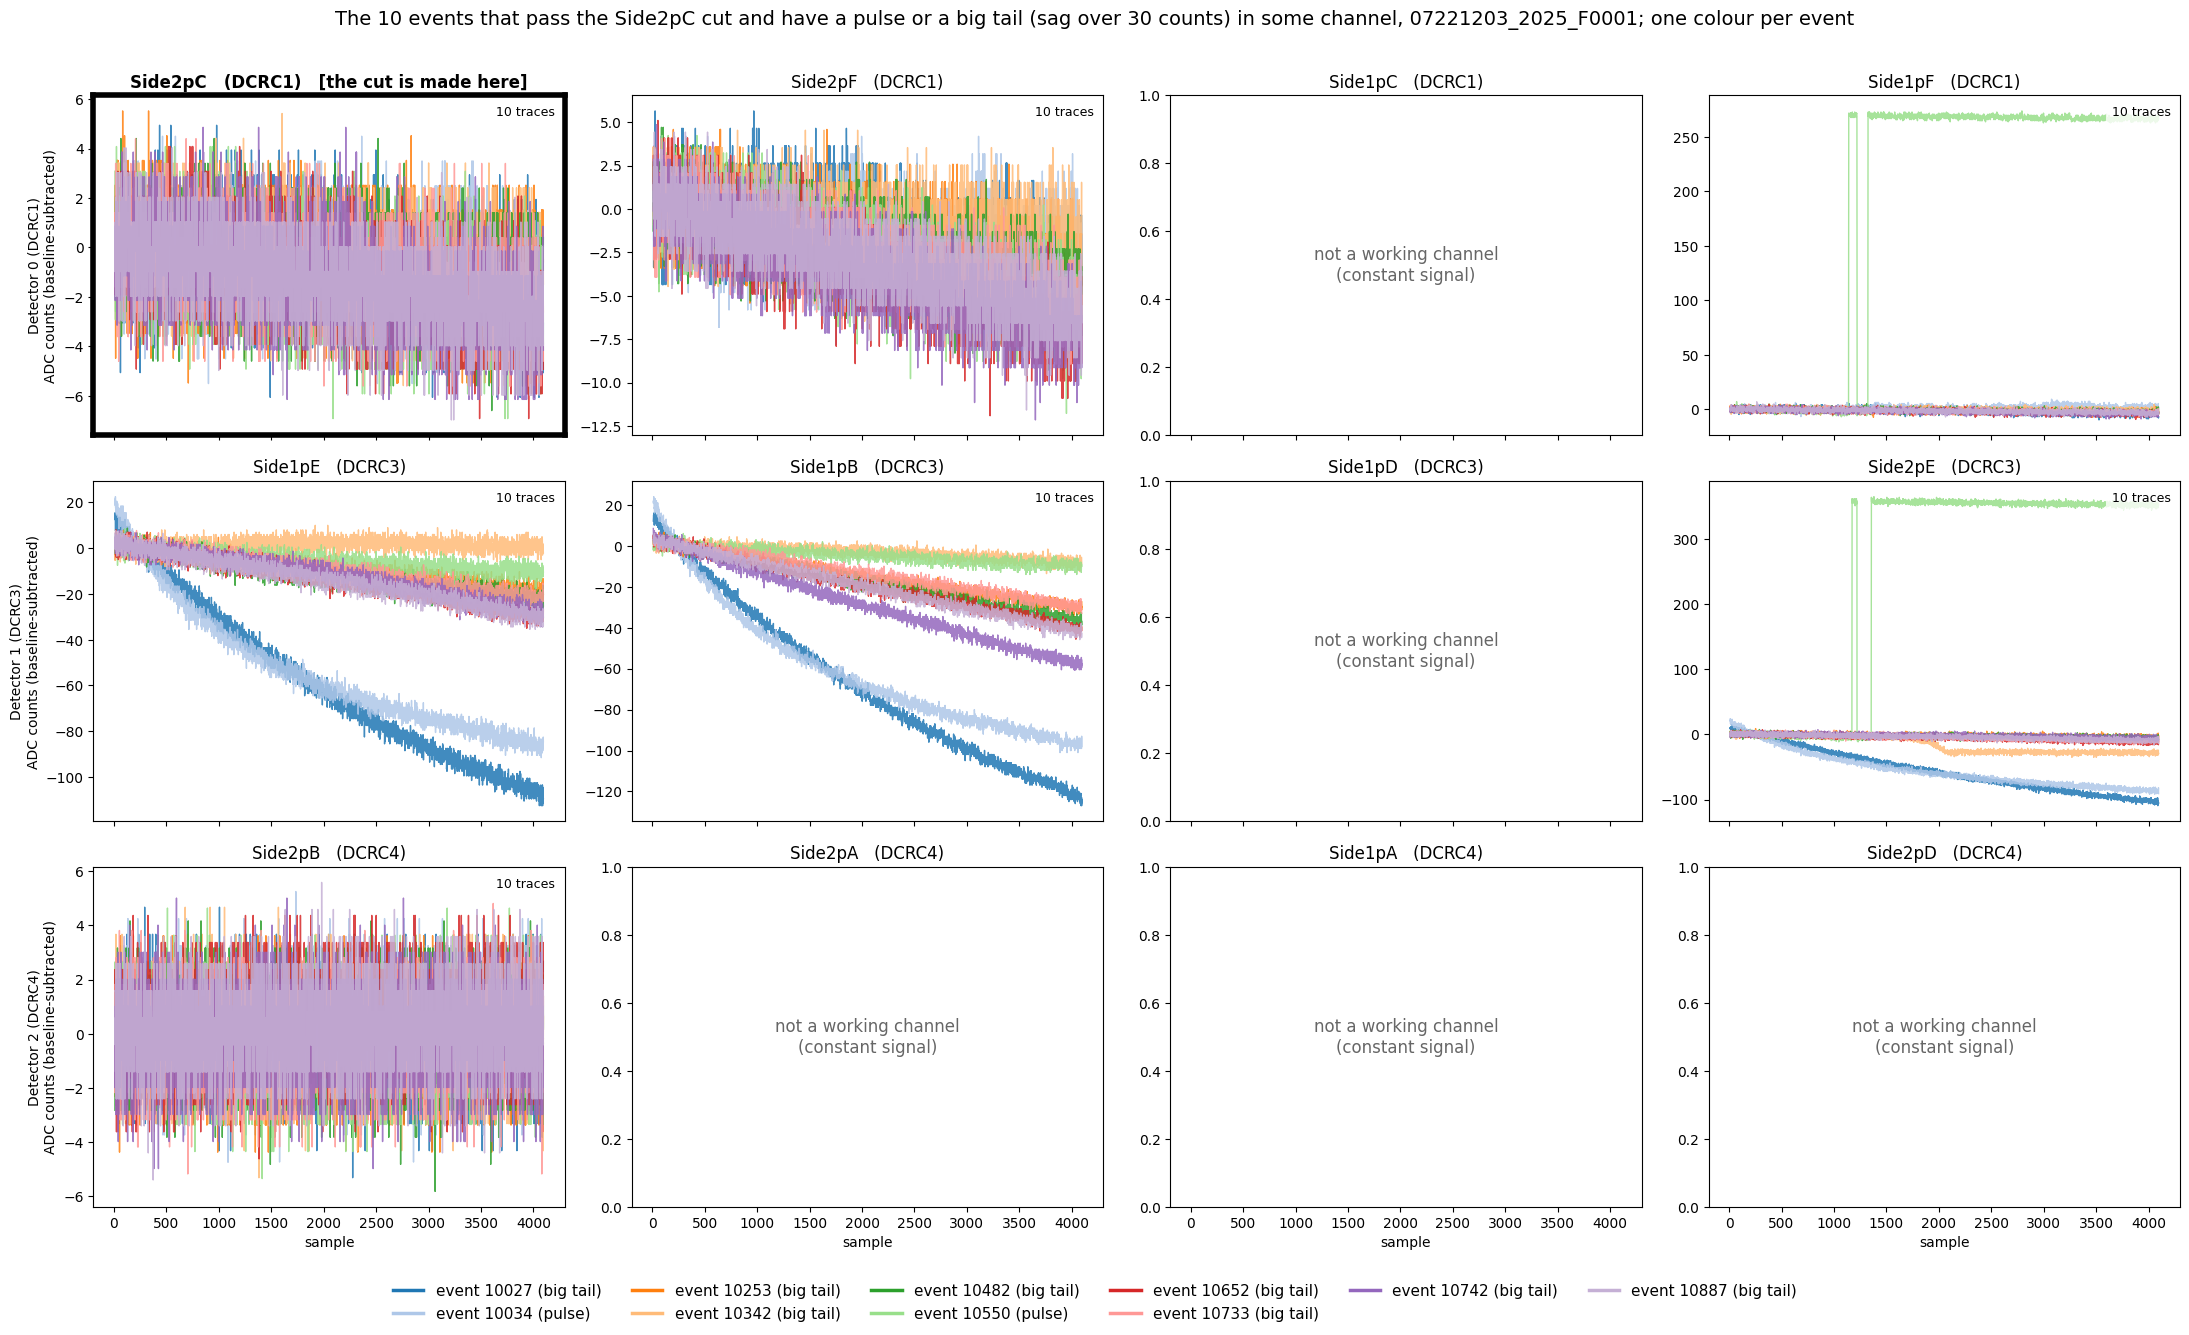

In [11]:
TAIL_DRIFT = -30          # a sag of more than this many counts across the trace counts as a big tail

drift_all = np.array([info[k]["drift"] for k in working])           # (working channels, events)
pulse_all = np.array([info[k]["pulse"] for k in working])
print(f"events that pass the Side2pC cut: {sel0.sum()}")
print(f"{'sag larger than (counts)':<28}{'events with a big tail':>24}")
for t in (-10, -20, -30, -50, -100):
    print(f"{-t:<28}{(sel0 & (drift_all <= t).any(axis=0)).sum():>24}")
print()

big_tail = (drift_all <= TAIL_DRIFT).any(axis=0)
has_pulse = pulse_all.any(axis=0)
selTP = sel0 & (big_tail | has_pulse)                               # <- passes the Side2pC cut, with a pulse or a big tail
print(f"with a pulse in some working channel: {(sel0 & has_pulse).sum()};  with a big tail (sag over {-TAIL_DRIFT} counts): {(sel0 & big_tail).sum()};"
      f"  either: {selTP.sum()}")
print()
print(f"{'event':>7}  {'pulse in':<40}{'worst sag':>10}  in channel")
for e in np.flatnonzero(selTP):
    pulses_in = [pch.channel_name(*k) for k, f in zip(working, pulse_all[:, e]) if f]
    j = int(np.argmin(drift_all[:, e]))
    print(f"{event_numbers[e]:>7}  {', '.join(pulses_in) or '-':<40}{drift_all[j, e]:>10.0f}  {pch.channel_name(*working[j])}")

def tile_figure_events(selection, cut_key, path):
    """The events of `selection` on every channel, one colour per event; the tile of `cut_key` is framed."""
    idx = np.flatnonzero(selection)
    colours = plt.cm.tab20(np.arange(len(idx)) % 20)
    fig, axes = plt.subplots(3, 4, figsize=(22, 13.5), sharex=True)
    for key in KEYS:
        det, ch = key
        ax = axes[det, ch]
        c = pch.channel_info(det, ch)
        is_cut = key == cut_key
        ax.set_title(f"{c.name}   ({c.dcrc})" + ("   [the cut is made here]" if is_cut else ""),
                     fontsize=12, fontweight="bold" if is_cut else "normal")
        if is_cut:
            for spine in ax.spines.values():
                spine.set_linewidth(4)
                spine.set_edgecolor("black")
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if key not in working:
            ax.text(0.5, 0.5, "not a working channel" + chr(10) + "(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        tr = processed(p[selection])
        xs = np.arange(glitch, glitch + tr.shape[-1])
        for trace, colour in zip(tr, colours):
            ax.plot(xs, trace, color=colour, linewidth=1.0, alpha=0.85)
        ax.text(0.98, 0.97, f"{len(tr)} traces", transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    handles = []
    for e, colour in zip(idx, colours):
        kind = "pulse" if has_pulse[e] else "big tail"
        handles.append(plt.Line2D([0], [0], color=colour, linewidth=2.5, label=f"event {event_numbers[e]} ({kind})"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 6), fontsize=11, frameon=False)
    fig.suptitle(f"The {len(idx)} events that pass the {pch.channel_name(*cut_key)} cut and have a pulse or a big tail "
                 f"(sag over {-TAIL_DRIFT} counts) in some channel, {DUMP}; one colour per event", fontsize=14)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    plt.savefig(path, dpi=100)
    plt.show()

tile_figure_events(selTP, (0, 0), f"figures/chan0-cut-with-pulses-or-big-tails-{DUMP}.png")

### 9.1 What these events look like (this dump only)

- **There are only a few: 10 of the 141 events (7%).** Two have a pulse and eight more have a baseline sag of more than 30 counts. The table above shows how many each threshold gives: 22 events sag by more than 10 counts, 15 by more than 20, 9 by more than 30, 3 by more than 50 and 1 by more than 100.
- **Two events have a pulse.** Event 10550 has a step of about 270 counts in `Side1pF` and 360 counts in `Side2pE` at about sample 1150, with a brief return towards zero before it steps up again, and nothing in the other channels. Event 10034 is a long decay in the three DCRC3 channels, down to about -100 counts, which is flagged as a pulse only because it is far from a straight line; it looks like the big tails of the other events, which is my reading of the shape.
- **The big tails are in DCRC3.** The sag is largest in `Side1pB` for 8 of the 10 events (up to 133 counts for event 10027) and in `Side2pE` or `Side1pE` for the other two. In `Side2pF` and `Side1pF`, on DCRC1, the same events sag by only a few counts.
- **None of these events can be seen in the channel the cut is made on.** In the framed `Side2pC` tile the 10 traces lie in the same noise band, and the same is true of `Side2pB` on DCRC4. This is why the `Side2pC` cut lets them through.

## 10. The events that pass the `Side1pB` cut but have a pulse or a big tail on Side 2

The same question as section 9, turned round. Start from the randoms that **pass the quiet-noise cut on `Side1pB`** (Side 1, `B_KEY` of section 7), and keep only those that have, in at least one **Side 2** working channel, a pulse or a big tail (a sag of more than `TAIL_DRIFT` counts, as in section 9). This shows what a cut made on Side 1 lets through on the other side of the detector.

Each event has its own colour, the same in every tile; the tile of `Side1pB` is framed, and the Side 2 tiles, where the pulse or tail is looked for, are titled in bold.

In [12]:
S1_KEY = B_KEY                                                    # the Side 1 channel the cut is made on
side2_rows = [i for i, k in enumerate(working) if pch.channel_info(*k).side == 2]
side2_keys = [working[i] for i in side2_rows]

selS1 = is_random & info[S1_KEY]["quiet"]                          # passes the cut on Side 1
tail_S2 = (drift_all[side2_rows] <= TAIL_DRIFT).any(axis=0)
pulse_S2 = pulse_all[side2_rows].any(axis=0)
selS1_S2 = selS1 & (tail_S2 | pulse_S2)                            # <- pulse or big tail on Side 2

print(f"events that pass the {pch.channel_name(*S1_KEY)} cut: {selS1.sum()}")
print(f"with a pulse in a Side 2 channel: {(selS1 & pulse_S2).sum()};  with a big tail (sag over {-TAIL_DRIFT} counts): {(selS1 & tail_S2).sum()};"
      f"  either: {selS1_S2.sum()}")
worst = drift_all[side2_rows][:, selS1].min()
print(f"the largest sag in any Side 2 channel among these events: {-worst:.0f} counts (the threshold is {-TAIL_DRIFT})")
print()
print(f"{'event':>7}  {'pulse in':<30}{'worst Side 2 sag':>17}  in channel")
for e in np.flatnonzero(selS1_S2):
    pulses_in = [pch.channel_name(*k) for k, i in zip(side2_keys, side2_rows) if pulse_all[i, e]]
    j = int(np.argmin(drift_all[side2_rows, e]))
    print(f"{event_numbers[e]:>7}  {', '.join(pulses_in) or '-':<30}{drift_all[side2_rows[j], e]:>17.0f}  {pch.channel_name(*side2_keys[j])}")

def tile_figure_events_from(selection, cut_key, looked_keys, path):
    """One colour per event, every channel; the tile of `cut_key` is framed, those of `looked_keys` have bold titles."""
    idx = np.flatnonzero(selection)
    colours = plt.cm.tab20(np.arange(len(idx)) % 20)
    fig, axes = plt.subplots(3, 4, figsize=(22, 13.5), sharex=True)
    for key in KEYS:
        det, ch = key
        ax = axes[det, ch]
        c = pch.channel_info(det, ch)
        is_cut = key == cut_key
        ax.set_title(f"{c.name}   ({c.dcrc})" + ("   [the cut is made here]" if is_cut else ""),
                     fontsize=12, fontweight="bold" if (is_cut or key in looked_keys) else "normal")
        if is_cut:
            for spine in ax.spines.values():
                spine.set_linewidth(4)
                spine.set_edgecolor("black")
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if key not in working:
            ax.text(0.5, 0.5, "not a working channel" + chr(10) + "(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        tr = processed(p[selection])
        xs = np.arange(glitch, glitch + tr.shape[-1])
        for trace, colour in zip(tr, colours):
            ax.plot(xs, trace, color=colour, linewidth=1.0, alpha=0.85)
        ax.text(0.98, 0.97, f"{len(tr)} traces", transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    handles = []
    for e, colour in zip(idx, colours):
        kind = "pulse" if pulse_S2[e] else "big tail"
        handles.append(plt.Line2D([0], [0], color=colour, linewidth=2.5, label=f"event {event_numbers[e]} ({kind})"))
    fig.legend(handles=handles, loc="lower center", ncol=min(max(len(handles), 1), 6), fontsize=11, frameon=False)
    fig.suptitle(f"The {len(idx)} events that pass the {pch.channel_name(*cut_key)} cut and have a pulse or a big tail "
                 f"(sag over {-TAIL_DRIFT} counts) in a Side 2 channel, {DUMP}; one colour per event", fontsize=14)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    plt.savefig(path, dpi=100)
    plt.show()

if selS1_S2.any():
    tile_figure_events_from(selS1_S2, S1_KEY, side2_keys, f"figures/chan0-side1-cut-with-side2-pulses-or-tails-{DUMP}.png")
else:
    print("no event to draw: nothing that passes the Side 1 cut has a pulse or a big tail on Side 2")

events that pass the Side1pB cut: 101
with a pulse in a Side 2 channel: 0;  with a big tail (sag over 30 counts): 0;  either: 0
the largest sag in any Side 2 channel among these events: 13 counts (the threshold is 30)

  event  pulse in                       worst Side 2 sag  in channel
no event to draw: nothing that passes the Side 1 cut has a pulse or a big tail on Side 2


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3753874653.py:2: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  side2_rows = [i for i, k in enumerate(working) if pch.channel_info(*k).side == 2]
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3753874653.py:10: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"events that pass the {pch.channel_name(*S1_KEY)} cut: {selS1.sum()}")


## 11. The `Side1pB` cut alone, on every channel

Section 10 found nothing that passes the `Side1pB` cut and has a pulse or a big tail on Side 2. Here is the cut on its own, as section 2 did for `Side2pC`: the 101 randoms that pass the quiet-noise cut on `Side1pB`, drawn over each other in every channel. Only the tile of `Side1pB`, the channel the cut is made on, is framed. The first figure is zoomed on the noise; the second is at full scale, so that any ramp would show.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:13: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3032829938.py:44: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  names = " and ".join(pch.channel_name(*k) for k in cut_keys)


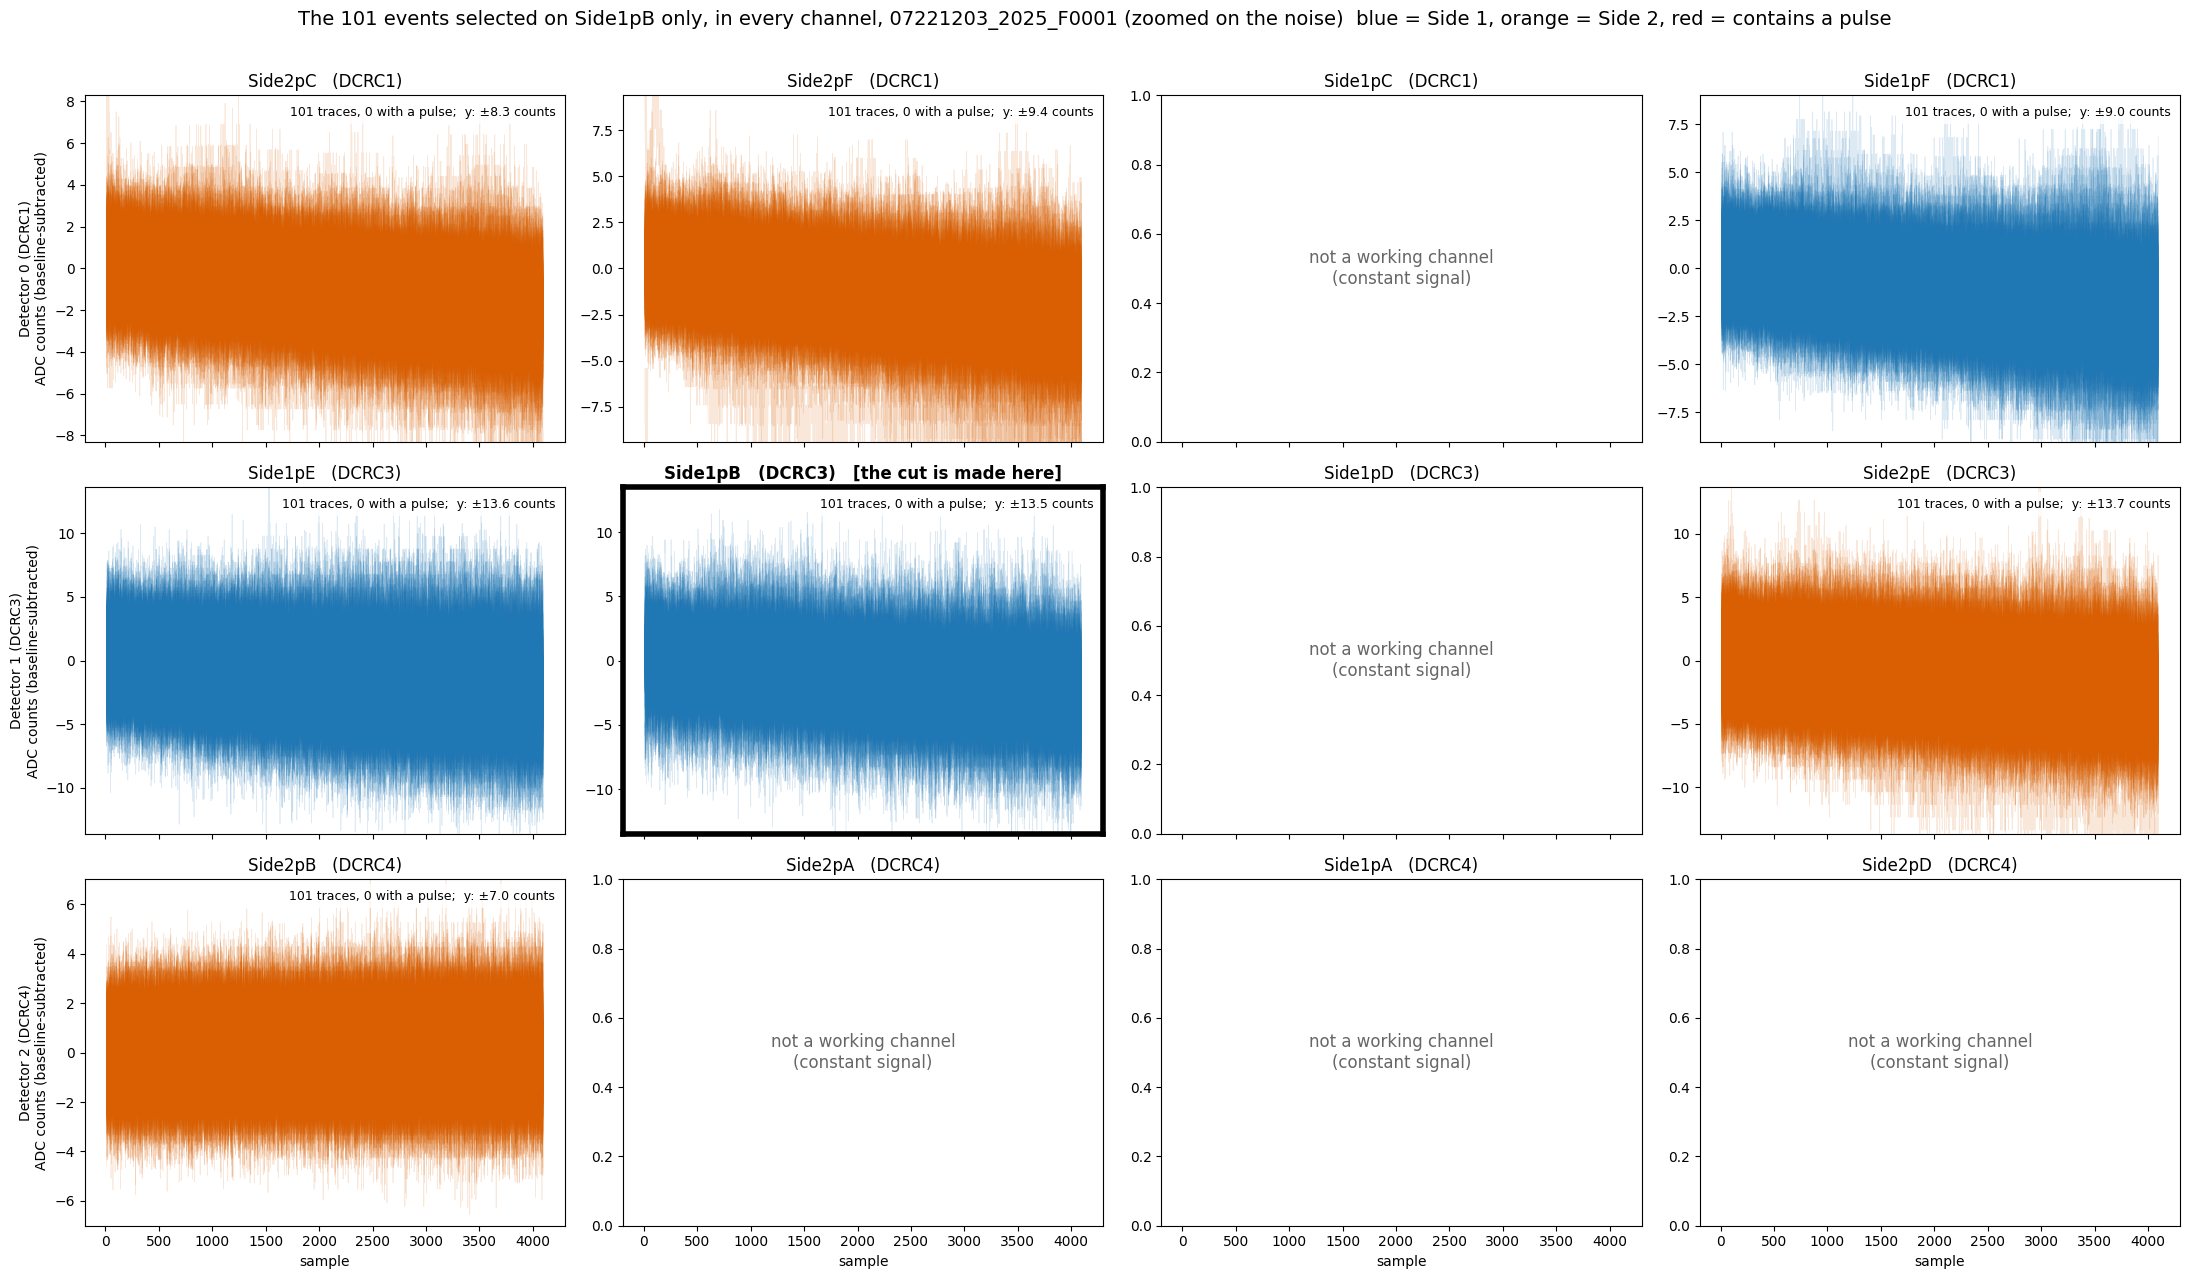

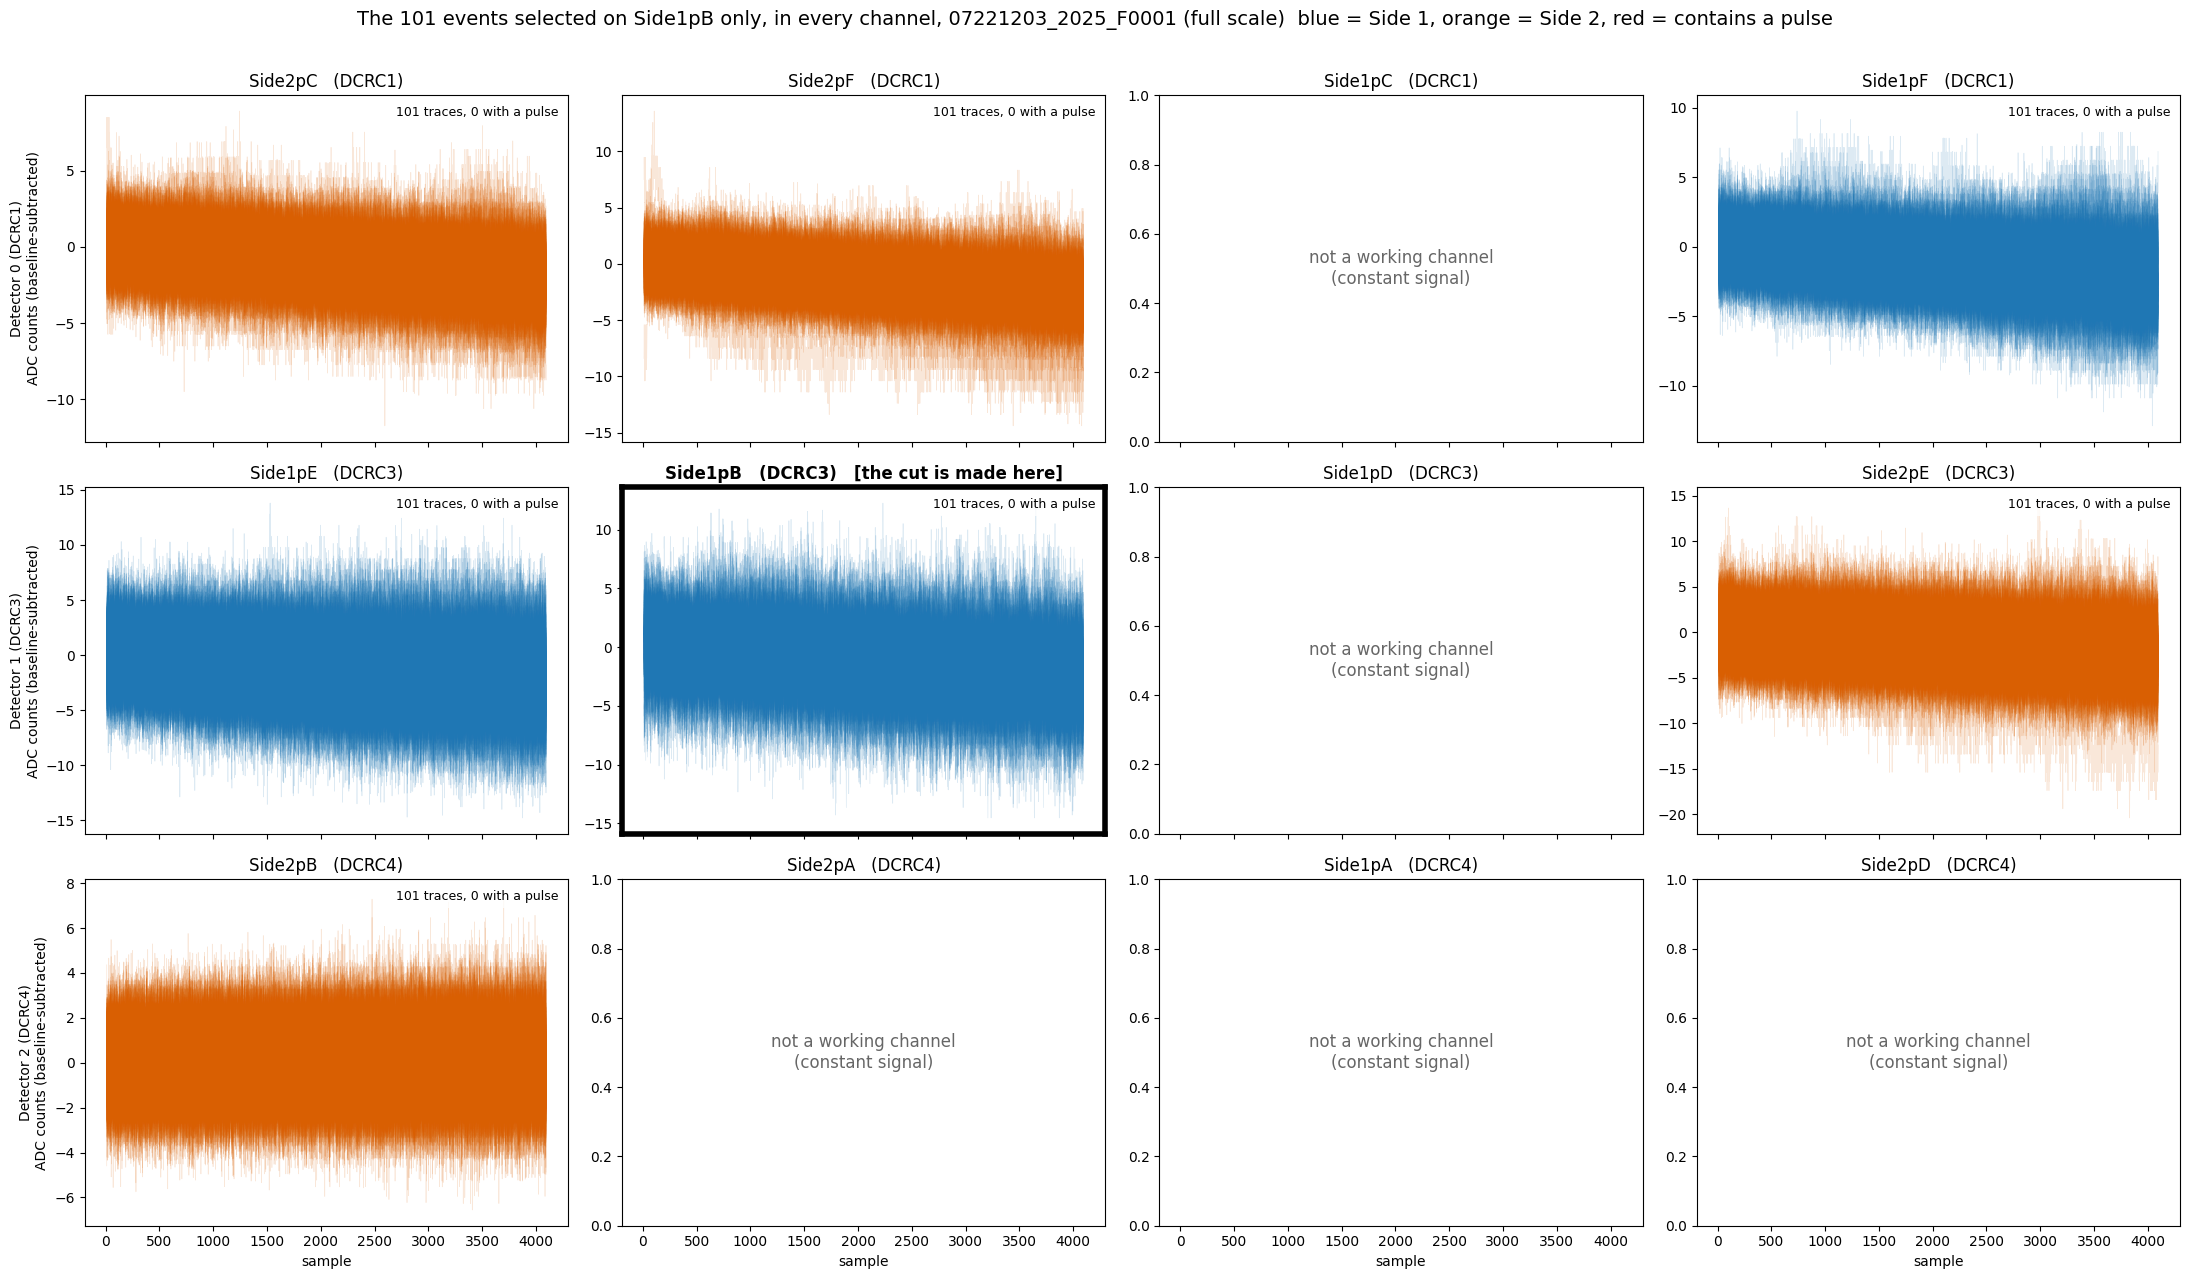

In [13]:
tile_figure_for(selS1, (S1_KEY,), zoom=True, path=f"figures/cut-on-S1-only-zoom-{DUMP}.png")
tile_figure_for(selS1, (S1_KEY,), zoom=False, path=f"figures/cut-on-S1-only-full-{DUMP}.png")

### 11.1 What the `Side1pB` cut gives (this dump only)

- **It keeps 101 of the 1008 randoms**, more than the cut on one channel of each side (71) and fewer than the `Side2pC` cut (141).
- **Section 10 found nothing on Side 2.** None of the 101 contains a pulse in any working channel, and the largest baseline sag in a Side 2 channel is 13 counts, where the threshold for a big tail is 30. The `Side2pC` cut, in contrast, let 10 events with a pulse or a big tail through (section 9).
- **The tiles look like noise.** At full scale every working channel stays within about 15 to 20 counts, with no ramps and no pulses.

## 12. The strictest cut: the traces of the 31 events that pass in every working channel

The global cut of section 5 keeps a random only if it passes the quiet-noise cut in every working channel. Here are all of its events in every channel, drawn over each other as in section 2, to check that they look like noise. No tile is framed, because the cut is made on all of them. The vertical scale is free, and a trace with a pulse would be drawn in red.

events that pass in every working channel: 31


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\3451508184.py:7: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  c = pch.channel_info(det, ch)


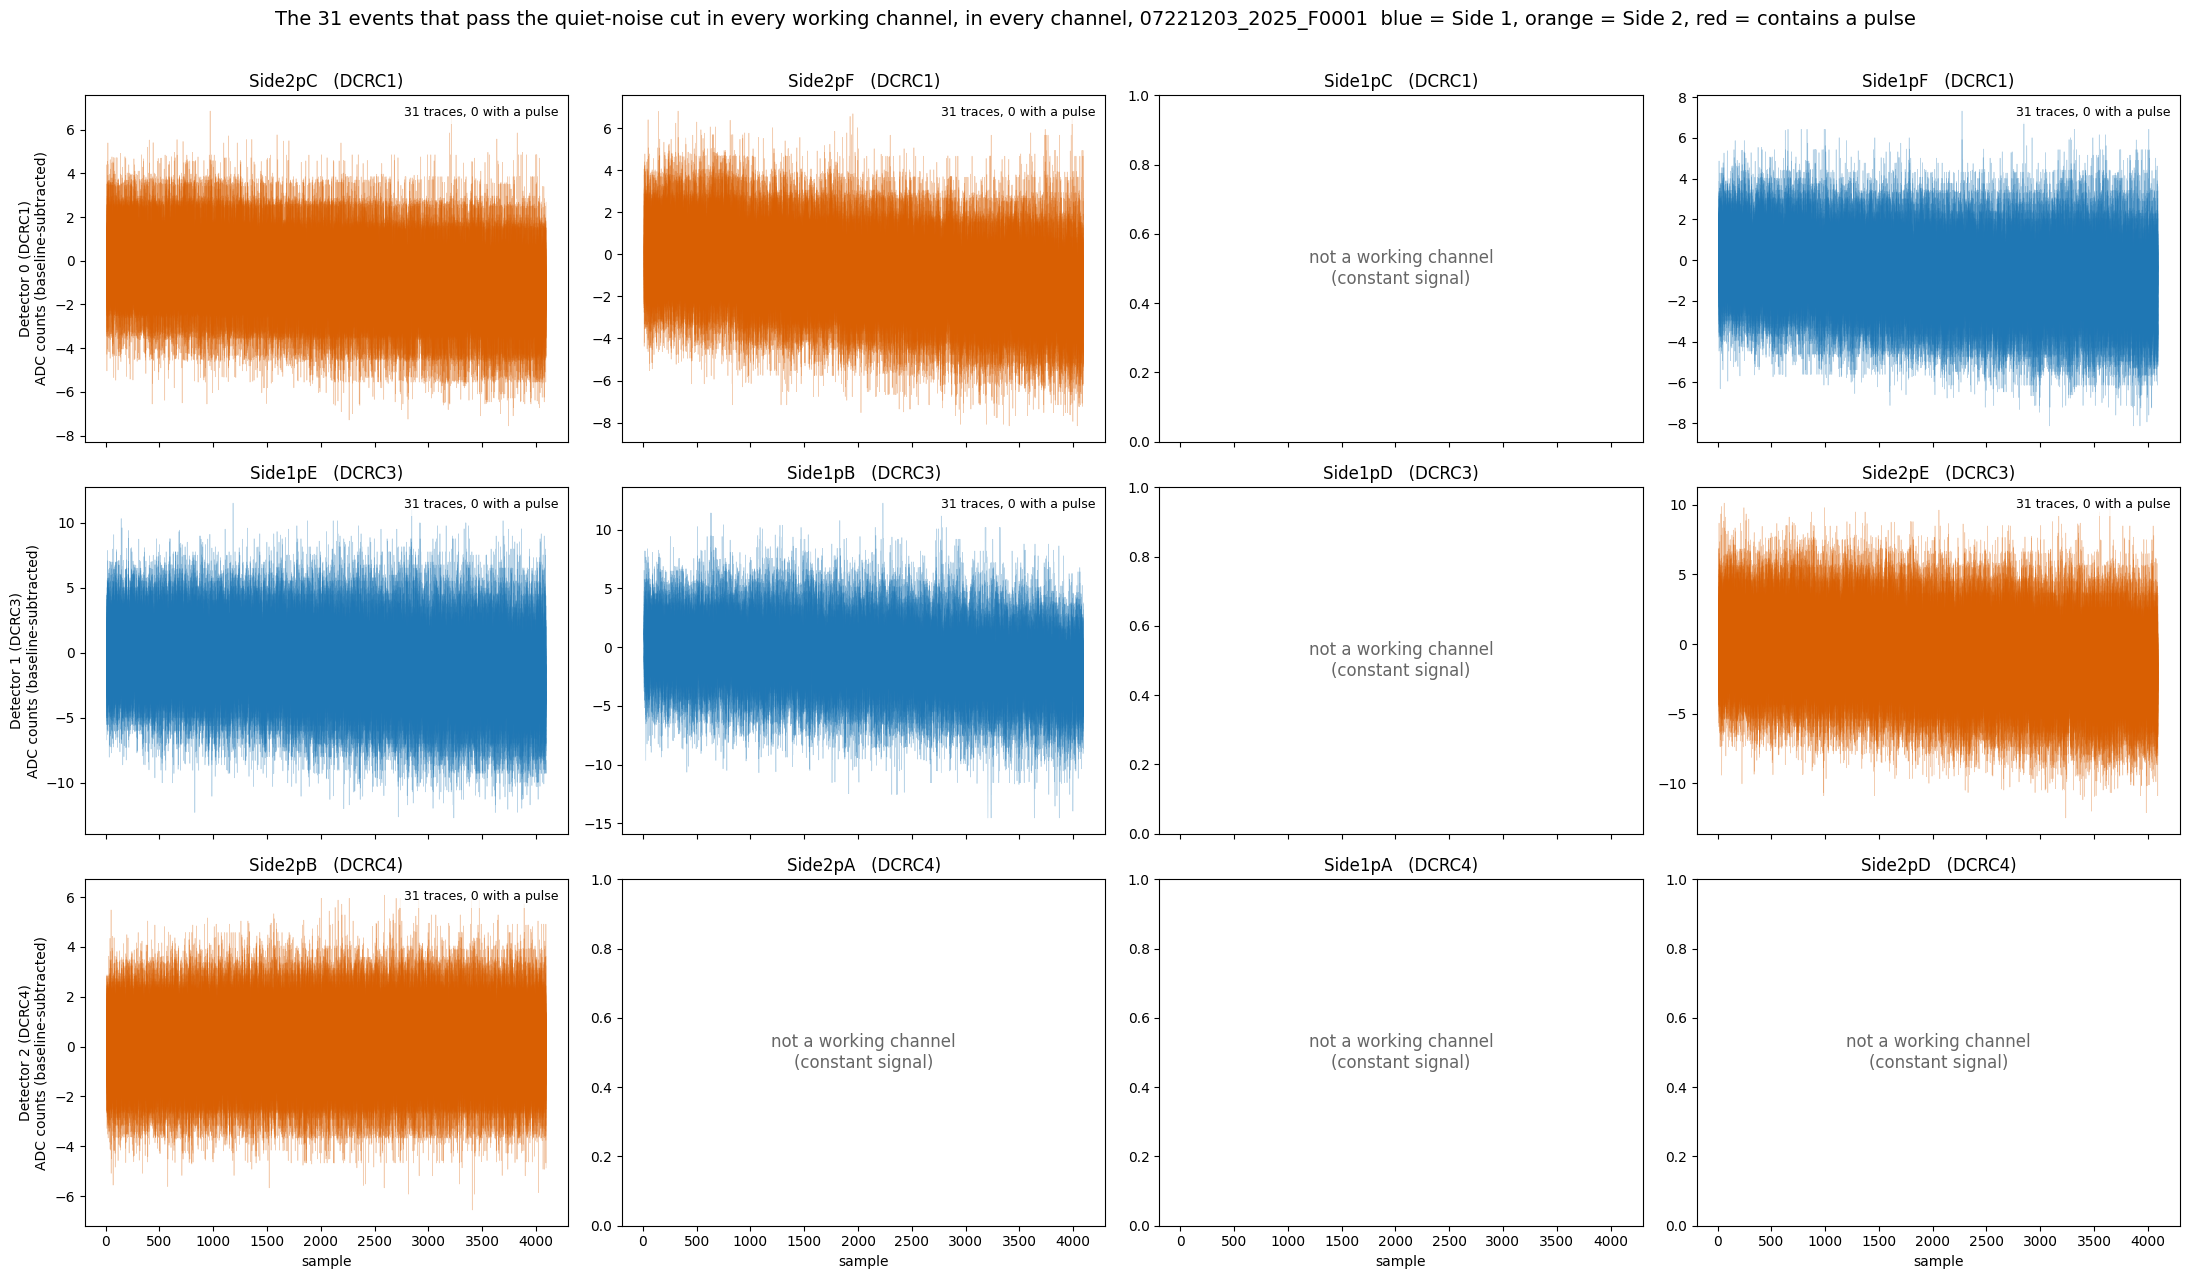

In [14]:
def tile_figure_global(selection, path):
    """All the events of `selection` over each other on every channel (no channel is singled out)."""
    fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True)
    for key in KEYS:
        det, ch = key
        ax = axes[det, ch]
        c = pch.channel_info(det, ch)
        ax.set_title(f"{c.name}   ({c.dcrc})", fontsize=12)
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({c.dcrc})" + chr(10) + "ADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if key not in working:
            ax.text(0.5, 0.5, "not a working channel" + chr(10) + "(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        tr = processed(p[selection])
        xs = np.arange(glitch, glitch + tr.shape[-1])
        pulse = info[key]["pulse"][selection]
        for trace in tr[~pulse]:
            ax.plot(xs, trace, color=side_colour[c.side], linewidth=0.5, alpha=0.3)
        for trace in tr[pulse]:
            ax.plot(xs, trace, color="crimson", linewidth=0.7, alpha=0.6)
        ax.text(0.98, 0.97, f"{len(tr)} traces, {pulse.sum()} with a pulse", transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
    fig.suptitle(f"The {selection.sum()} events that pass the quiet-noise cut in every working channel, in every channel, {DUMP}"
                 "  blue = Side 1, orange = Side 2, red = contains a pulse", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.savefig(path, dpi=100)
    plt.show()

print(f"events that pass in every working channel: {global_keep.sum()}")
tile_figure_global(global_keep, f"figures/global-cut-traces-{DUMP}.png")

## 13. The cut we will use: `clean_randoms`

The cut of Notes 2 and 2a, made on `Side1pB` instead of `Side2pC`: a **random** trigger (`pc.randoms`, with the swapped-label caveat above) whose trace on `Side1pB` (Detector 1 / Channel 1) falls in the Tight excursion band of the 500-sample pretrigger window and has `log10(bstd) < 0.5`. Sections 10 and 11 show that this selection is free of pulses and of big tails on both sides, and it keeps 101 randoms, more than the stricter cuts. The cell below defines it in one place as `clean_randoms` and checks that it is the selection of section 10.

In [15]:
CLEAN_KEY = (1, 1)        # Side1pB (DCRC3), the channel the cut is made on

def clean_randoms_cut(pulses, trigger_types, config=config_500):
    """Randoms with no pulse: the Note 2 / 2a cut (Tight excursion band and log10(bstd) < 0.5) on one channel."""
    with np.errstate(all="ignore"):
        quiet = pc.excursion_band(pulses, config) & (np.log10(pq.bstd(pulses, config)) < 0.5)
    return pc.randoms(trigger_types) & quiet

_, p_clean = pio.load_channel_batch(cdms, det_ids[CLEAN_KEY[0]], CLEAN_KEY[1])
clean_randoms = clean_randoms_cut(p_clean, pio.trigger_types(cdms, det_ids[CLEAN_KEY[0]]))   # <- the cut we use from now on
assert np.array_equal(clean_randoms, selS1)                         # the selection of sections 10 and 11
print(f"clean_randoms on {short_label(*CLEAN_KEY)}: {clean_randoms.sum()} of the {is_random.sum()} randoms")
print("event numbers:", " ".join(str(n) for n in event_numbers[clean_randoms]))

clean_randoms on Side1pB (DCRC3): 101 of the 1008 randoms
event numbers: 10001 10002 10008 10010 10029 10031 10035 10045 10049 10055 10058 10062 10147 10153 10177 10183 10185 10189 10193 10204 10206 10214 10220 10222 10227 10257 10262 10275 10282 10291 10298 10302 10304 10314 10333 10338 10339 10357 10393 10397 10408 10421 10422 10427 10428 10437 10440 10459 10462 10475 10476 10480 10481 10488 10489 10506 10510 10532 10533 10538 10542 10548 10553 10554 10557 10561 10564 10569 10576 10578 10596 10618 10629 10655 10662 10718 10735 10736 10759 10770 10794 10800 10828 10833 10856 10859 10866 10883 10908 10913 10914 10928 10934 10943 10958 10961 10965 10967 10975 10983 10995


C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\683272392.py:7: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  return pc.randoms(trigger_types) & quiet
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24572\1258918606.py:21: UserWarning: channel_info is marked under_development: 

## Next steps

- Read the figures above and the tables, and write down how good the Channel 0 cut is on each channel.
- If most of the rejected events are ramps, check whether the drift of Channel 0 itself separates the kept events from the rejected ones, which would say why the Channel 0 cut lets them through.
- If some events contain a pulse in another channel only, look at them in the time domain: is the pulse in the same place in every channel it appears in?
- Decide whether the noise note should use the Channel 0 selection, the global cut, or a cut on the drift.
- Repeat with the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`.